# Instance Segmentation Inference, Evaluation & Failure Analysis (`myroom/` Test Set)

This notebook evaluates all trained checkpoints in `content/` on your **40 self-captured & self-annotated `myroom/` test photos**, builds a **2-part Task 4 Failure Analysis** using the **best model from Part 1** and the **best model from Part 2** across all 40 test images, and provides a **1-cell Interactive Inference Playground**.

### Evaluation Structure

| Part | Folder | Resolution | Models Compared |
|------|--------|------------|-----------------|
| **Part 1 — Model Comparison** | `content/outputs/` | `512 × 512` (letterbox) | **YOLO11n-seg**, **Mask R-CNN (R50-FPN v2)**, **Mask2Former (Swin-T)** |
| **Part 2 — Augmentation Comparison** | `content/outputs_augmentation/` | `640 × 640` (letterbox) | **Mask2Former (No Aug)**, **Mask2Former (Aug 1)**, **Mask2Former (Aug 2)** |

### Sections
- **0–1.** Environment, GPU/AMP setup, and centralized configuration / model registry.
- **2.** `myroom/` dataset preprocessing (EXIF fix, letterboxing to 512 & 640, **automatic class-name remapping** from `myroom`'s 24 Roboflow IDs into the 74-class training taxonomy, COCO JSON generation).
- **3.** Unified model loaders, inference wrappers, COCO mAP / per-class AP evaluators, and visualization utilities.
- **4.** **Part 1 — Model Comparison** (mAP table, domain-shift vs original `val`, per-class AP, qualitative overview).
- **5.** **Part 2 — Augmentation Comparison** (mAP table, domain-shift vs original `val`, per-class AP, qualitative overview).
- **6.** **Task 4 — Evidence-Based Failure Analysis (2 Parts: Best Model from Part 1 & Best Model from Part 2)**:
  - **6.1** Select best model from Part 1 & Part 2 + automated failure audit across all 40 `myroom/` test photos (**Missed / FN**, **Wrong Class**, **Mask Leakage**, **Split Object**).
  - **6.2 Task 4 — Part A:** Display **all 40 `myroom/` test images** (`GT | Prediction | Pixel Error Map`) + full 40-row table for the **Best Model from Part 1** so you can inspect and analyze every photo yourself.
  - **6.3 Task 4 — Part B:** Display **all 40 `myroom/` test images** (`GT | Prediction | Pixel Error Map`) + full 40-row table for the **Best Model from Part 2** so you can inspect and analyze every photo yourself.
  - **6.4** 5-photo comparison sheet (`Best Part 1` vs `Best Part 2`) for your chosen failure photos + Mini Proof Experiments (**Exp A:** threshold sweep, **Exp B:** zoom/crop resolution test, **Exp C:** CLAHE/gamma lighting test).
- **7.** **Interactive Inference Playground (1 Customizable Cell)** — tweak model, image, confidence/mask/IoU thresholds, class filters, and display options in one place.

## 0. Environment & Imports

Works both locally (Windows / WSL / Linux) and in Google Colab. If running in Colab, uncomment the Drive mount lines if your files live on Google Drive.

In [2]:
# Optional: uncomment if running on Google Colab with files in Google Drive
from google.colab import drive
drive.mount("/content/drive")

import contextlib
import gc
import io
import json
import math
import os
import random
import shutil
import sys
import time
import warnings
from collections import Counter, defaultdict
from dataclasses import dataclass, field
from pathlib import Path

os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

import cv2
cv2.setNumThreads(0)
cv2.ocl.setUseOpenCL(False)

import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
import numpy as np
import pandas as pd
import torch
import torchvision
import yaml
from PIL import Image, ImageOps
from tqdm.auto import tqdm

from torchvision.models.detection import maskrcnn_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

from transformers import Mask2FormerForUniversalSegmentation, Mask2FormerImageProcessor
from ultralytics import YOLO

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
import pycocotools.mask as mask_utils

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42


def seed_everything(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.benchmark = False


seed_everything()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
GPU_VRAM_GB = torch.cuda.get_device_properties(0).total_memory / 1e9 if DEVICE.type == "cuda" else 0.0
USE_BF16 = (
    DEVICE.type == "cuda"
    and torch.cuda.get_device_capability(0)[0] >= 8
    and torch.cuda.is_bf16_supported()
)


def amp_ctx():
    if not USE_AMP:
        return contextlib.nullcontext()
    dtype = torch.bfloat16 if USE_BF16 else torch.float16
    return torch.autocast("cuda", dtype=dtype)


def free_gpu():
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


print(f"python      : {sys.version.split()[0]}")
print(f"torch       : {torch.__version__}")
print(f"torchvision : {torchvision.__version__}")
print(f"device      : {DEVICE}")
if DEVICE.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    cc = torch.cuda.get_device_capability(0)
    print(f"gpu         : {props.name} ({GPU_VRAM_GB:.1f} GB, CC {cc[0]}.{cc[1]})")
    print(f"amp dtype   : {'bfloat16' if USE_BF16 else 'float16'}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
python      : 3.13.16
torch       : 2.11.0+cu130
torchvision : 0.26.0+cu130
device      : cuda
gpu         : Tesla T4 (15.6 GB, CC 7.5)
amp dtype   : float16


## 1. Configuration & Model Registry

All folder paths, model checkpoints, class alias rules, and evaluation thresholds live here.

> **Important Note on Class Remapping (`myroom/` vs Training Taxonomy):**
> Roboflow exported `myroom/data.yaml` with **24 re-indexed classes (`0..23`)**, whereas all 6 trained models in `content/` output **74-class indices (`0..73`)** from `panoptic-indoor-segmentation`.
> This notebook automatically remaps every `myroom` ground-truth polygon by **class name** into the 74-class training taxonomy.
> - `"table"` (22 instances in `myroom`) is mapped to `"table-merged"` (class 54 in training, 711 training instances) via `CLASS_ALIAS_MAP`.
> - `"wall"` (11 instances in `myroom`) matches training class 65 (`"wall"`, which had only 2 training instances vs 1,721 `"wall-other-merged"` instances). Keep it as exact match or uncomment the alias below to test merging it.

In [5]:
PROJECT_DIR = Path.cwd().resolve()


def _resolve_dir(*candidates):
    for c in candidates:
        p = Path(c)
        if p.is_dir():
            return p.resolve()
    return Path(candidates[0]).resolve()


CONTENT_DIR = _resolve_dir(PROJECT_DIR / "content", Path("/content"))
MYROOM_DIR = _resolve_dir(PROJECT_DIR / "myroom", Path("/content/myroom"))
TRAIN_DATASET_DIR = _resolve_dir(
    PROJECT_DIR / "panoptic-indoor-segmentation.v1-forked-v5.yolov8-obb",
    Path("/content/panoptic-indoor-segmentation.v1-forked-v5.yolov8-obb"),
)

OUT_DIR = PROJECT_DIR / "inference_outputs"
for sub in ("part1_models/preds", "part2_augmentation/preds", "failure_analysis", "playground"):
    (OUT_DIR / sub).mkdir(parents=True, exist_ok=True)

# Preprocessing & evaluation settings
RESIZE_MODE = "pad"          # "pad" = letterbox (matches training) | "stretch"
PAD_VALUE = 114              # grey padding used during training
REBUILD_MYROOM_CACHE = False # set True to force regenerating 512 & 640 cached datasets

# Class name aliases when mapping myroom/data.yaml -> 74-class training taxonomy
CLASS_ALIAS_MAP = {
    "table": "table-merged",
    # "wall": "wall-other-merged",  # Optional: training set has only 2 'wall' vs 1721 'wall-other-merged'
}

# Batch sizes (safe for 6 GB VRAM laptops and Colab GPUs alike)
EVAL_BATCH_SIZE = {
    "yolo": 8,
    "maskrcnn": 2 if GPU_VRAM_GB < 10 else 4,
    "mask2former": 2 if GPU_VRAM_GB < 10 else 4,
}

# Inference thresholds for COCO mAP evaluation (low threshold -> full PR curve)
COCO_EVAL_THR = {
    "yolo": {"conf": 0.001, "iou": 0.60, "max_det": 100},
    "maskrcnn": {"score_thr": 0.05, "mask_thr": 0.50, "max_det": 100},
    "mask2former": {"score_thr": 0.0, "mask_thr": 0.50, "max_det": 100},
}

# Default operating thresholds for qualitative visualization & failure-mode auditing
VIS_THR = {
    "yolo": 0.35,
    "maskrcnn": 0.50,
    "mask2former": 0.50,
}

# Model registry for Part 1 (Model Comparison) and Part 2 (Augmentation Comparison)
MODEL_REGISTRY = {
    # --- Part 1: Model Architecture Comparison (512 x 512) ---
    "yolo": {
        "part": "part1",
        "label": "YOLO11n-seg",
        "arch": "yolo",
        "img_size": 512,
        "path": CONTENT_DIR / "outputs/yolo/yolo11n_seg_512/weights/best.pt",
        "default_conf": VIS_THR["yolo"],
    },
    "maskrcnn": {
        "part": "part1",
        "label": "Mask R-CNN (R50-FPN)",
        "arch": "maskrcnn",
        "img_size": 512,
        "path": CONTENT_DIR / "outputs/maskrcnn/best.pt",
        "default_conf": VIS_THR["maskrcnn"],
    },
    "mask2former": {
        "part": "part1",
        "label": "Mask2Former (Swin-T)",
        "arch": "mask2former",
        "img_size": 512,
        "path": CONTENT_DIR / "outputs/mask2former",
        "default_conf": VIS_THR["mask2former"],
    },
    # --- Part 2: Augmentation Strategy Comparison (640 x 640) ---
    "m2f_no_aug": {
        "part": "part2",
        "label": "Mask2Former (No Aug)",
        "arch": "mask2former",
        "img_size": 640,
        "path": CONTENT_DIR / "outputs_augmentation/mask2former_no_aug",
        "default_conf": VIS_THR["mask2former"],
    },
    "m2f_aug_1": {
        "part": "part2",
        "label": "Mask2Former (Aug 1)",
        "arch": "mask2former",
        "img_size": 640,
        "path": CONTENT_DIR / "outputs_augmentation/mask2former_aug_1",
        "default_conf": VIS_THR["mask2former"],
    },
    "m2f_aug_2": {
        "part": "part2",
        "label": "Mask2Former (Aug 2)",
        "arch": "mask2former",
        "img_size": 640,
        "path": CONTENT_DIR / "outputs_augmentation/mask2former_aug_2",
        "default_conf": VIS_THR["mask2former"],
    },
}

PART1_KEYS = [k for k, v in MODEL_REGISTRY.items() if v["part"] == "part1"]
PART2_KEYS = [k for k, v in MODEL_REGISTRY.items() if v["part"] == "part2"]

ORIG_METRICS_PART1 = CONTENT_DIR / "outputs/metrics_segm.csv"
ORIG_METRICS_PART2 = CONTENT_DIR / "outputs_augmentation/metrics_segm.csv"

print(f"PROJECT_DIR : {PROJECT_DIR}")
print(f"CONTENT_DIR : {CONTENT_DIR}")
print(f"MYROOM_DIR  : {MYROOM_DIR}")
print(f"OUT_DIR     : {OUT_DIR}\n")

status_rows = []
for key, cfg in MODEL_REGISTRY.items():
    p = cfg["path"]
    ok = (p / "config.json").is_file() if cfg["arch"] == "mask2former" else p.is_file()
    status_rows.append({
        "key": key,
        "part": cfg["part"],
        "label": cfg["label"],
        "arch": cfg["arch"],
        "img_size": cfg["img_size"],
        "exists": ok,
        "path": str(p),
    })

status_df = pd.DataFrame(status_rows)
display(status_df)
missing = status_df[~status_df["exists"]]
if len(missing):
    raise FileNotFoundError(f"Missing model checkpoints:\n{missing[['key', 'path']].to_string(index=False)}")

PROJECT_DIR : /content
CONTENT_DIR : /content/content
MYROOM_DIR  : /content/myroom
OUT_DIR     : /content/inference_outputs



,key,part,label,arch,img_size,exists,path
0,yolo,part1,YOLO11n-seg,yolo,512,True,/content/content/outputs/yolo/yolo11n_seg_512/...
1,maskrcnn,part1,Mask R-CNN (R50-FPN),maskrcnn,512,True,/content/content/outputs/maskrcnn/best.pt
2,mask2former,part1,Mask2Former (Swin-T),mask2former,512,True,/content/content/outputs/mask2former
3,m2f_no_aug,part2,Mask2Former (No Aug),mask2former,640,True,/content/content/outputs_augmentation/mask2for...
4,m2f_aug_1,part2,Mask2Former (Aug 1),mask2former,640,True,/content/content/outputs_augmentation/mask2for...
5,m2f_aug_2,part2,Mask2Former (Aug 2),mask2former,640,True,/content/content/outputs_augmentation/mask2for...


## 2. Prepare `myroom/` Evaluation Dataset & Class Remapping

This section:
1. Loads the **74-class training taxonomy** (from `panoptic-indoor-segmentation.../data.yaml`, falling back to `maskrcnn/best.pt["classes"]` if the training dataset folder is absent).
2. Reads `myroom/data.yaml` and maps each of the 24 Roboflow classes by **name** into the 74-class training taxonomy (applying `CLASS_ALIAS_MAP`).
3. Builds letterboxed evaluation caches at **`512 × 512`** (for Part 1) and **`640 × 640`** (for Part 2), along with remapped YOLO polygon labels and COCO JSON ground-truth files (`instances_myroom_512.json` and `instances_myroom_640.json`).
4. Displays dataset statistics, EXIF/resolution summary, class mapping diagnostics, and a ground-truth sanity check.

In [11]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
MEAN = np.array([0.485, 0.456, 0.406], np.float32)
STD = np.array([0.229, 0.224, 0.225], np.float32)

# 20 portrait photos from myfoto.zip had EXIF Orientation=6 (90 deg CW) stripped by Roboflow
# when exported without Auto-Orient. This idempotent helper rotates them 90 deg CW ONLY if
# the JPEG is still sideways (W > H), so it works on both unfixed Colab copies and fixed local copies.
MYROOM_EXIF6_PREFIXES = {
    "20261117_183042", "20261117_183045", "20261117_183052", "20261117_183315",
    "20261117_183329", "20261117_183831", "20261117_183839", "20261117_183849",
    "20261117_183901", "20261117_183915", "20261117_183922", "20261117_183957",
    "20261117_184024", "20261117_184035", "20261117_184214", "20261117_184220",
    "20261117_184238", "20261117_184303", "20261117_184317", "20261117_184333",
}


def open_oriented_rgb(path: Path | str) -> Image.Image:
    p = Path(path)
    with Image.open(p) as im:
        im = ImageOps.exif_transpose(im).convert("RGB")
    prefix = p.name.split("_jpg.rf.")[0]
    if prefix in MYROOM_EXIF6_PREFIXES and im.width > im.height:
        im = im.transpose(Image.Transpose.ROTATE_270)  # 90 deg clockwise
    return im


def load_yaml_names(yaml_path: Path) -> list[str]:
    names = (yaml.safe_load(yaml_path.read_text(encoding="utf-8")) or {}).get("names")
    if isinstance(names, dict):
        return [str(names[k]) for k in sorted(names, key=int)]
    return [str(n) for n in (names or [])]


def load_training_class_names() -> list[str]:
    yaml_cand = TRAIN_DATASET_DIR / "data.yaml"
    if yaml_cand.is_file():
        return load_yaml_names(yaml_cand)
    mrcnn_path = MODEL_REGISTRY["maskrcnn"]["path"]
    ckpt = torch.load(mrcnn_path, map_location="cpu", weights_only=False)
    if "classes" in ckpt:
        return list(ckpt["classes"])
    raise FileNotFoundError("Could not find 74-class names in data.yaml or maskrcnn/best.pt.")


CLASS_NAMES = load_training_class_names()
NUM_CLASSES = len(CLASS_NAMES)
TRAIN_NAME_TO_ID = {name: idx for idx, name in enumerate(CLASS_NAMES)}

MYROOM_YAML = MYROOM_DIR / "data.yaml"
MYROOM_RAW_NAMES = load_yaml_names(MYROOM_YAML)

# Build myroom_id -> train_id mapping
MYROOM_TO_TRAIN_ID = {}
UNMAPPED_MYROOM_CLASSES = []
for mid, raw_name in enumerate(MYROOM_RAW_NAMES):
    target_name = CLASS_ALIAS_MAP.get(raw_name, raw_name)
    if target_name in TRAIN_NAME_TO_ID:
        MYROOM_TO_TRAIN_ID[mid] = TRAIN_NAME_TO_ID[target_name]
    else:
        UNMAPPED_MYROOM_CLASSES.append((mid, raw_name))


def parse_label_line(line: str):
    parts = line.split()
    if len(parts) < 5:
        return None
    try:
        cls = int(float(parts[0]))
        vals = np.asarray([float(v) for v in parts[1:]], dtype=np.float32)
    except ValueError:
        return None
    if vals.size < 4 or vals.size % 2 != 0:
        return None
    if vals.size == 4:
        cx, cy, w, h = vals
        poly = np.array([
            [cx - w / 2, cy - h / 2],
            [cx + w / 2, cy - h / 2],
            [cx + w / 2, cy + h / 2],
            [cx - w / 2, cy + h / 2],
        ], dtype=np.float32)
        return cls, poly, "bbox"
    return cls, vals.reshape(-1, 2), "polygon"


def read_labels(path, width: int, height: int, class_map: dict | None = None):
    if path is None or not Path(path).is_file():
        return []
    out = []
    for raw in Path(path).read_text(encoding="utf-8").splitlines():
        parsed = parse_label_line(raw) if raw.strip() else None
        if parsed is None:
            continue
        cls, poly, kind = parsed
        if class_map is not None:
            if cls not in class_map:
                continue
            cls = class_map[cls]
        if poly.max() > 1.5:
            poly = poly / np.array([width, height], dtype=np.float32)
        poly = np.clip(poly, 0.0, 1.0) * np.array([width, height], dtype=np.float32)
        if kind == "polygon" and abs(cv2.contourArea(poly)) < 4:
            continue
        out.append({"cls": int(cls), "poly": poly, "kind": kind})
    return out


def letterbox_image(im: Image.Image, size: int, mode: str = "pad", pad_value: int = 114):
    W, H = im.size
    if mode == "stretch":
        return im.resize((size, size), Image.BILINEAR), (size / W, size / H, 0, 0)
    ratio = min(size / W, size / H)
    nw, nh = max(1, int(round(W * ratio))), max(1, int(round(H * ratio)))
    dx, dy = (size - nw) // 2, (size - nh) // 2
    out = Image.new("RGB", (size, size), (pad_value,) * 3)
    out.paste(im.resize((nw, nh), Image.BILINEAR), (dx, dy))
    return out, (ratio, ratio, dx, dy)


def letterbox_and_scale(im: Image.Image, polys_px, size: int, mode: str = "pad", pad_value: int = 114):
    out_im, (sx, sy, dx, dy) = letterbox_image(im, size, mode=mode, pad_value=pad_value)
    scale = np.array([sx, sy], dtype=np.float32)
    shift = np.array([dx, dy], dtype=np.float32)
    return out_im, [p * scale + shift for p in polys_px]


def discover_myroom_split(myroom_root: Path):
    for cand in ("test", "valid", "val", "train", "."):
        base = myroom_root / cand if cand != "." else myroom_root
        img_dir = base / "images" if (base / "images").is_dir() else base
        lbl_dir = base / "labels" if (base / "labels").is_dir() else None
        imgs = sorted(p for p in img_dir.glob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTS)
        if imgs:
            return img_dir, lbl_dir, imgs
    raise FileNotFoundError(f"No images found under {myroom_root}")


MYROOM_IMG_DIR, MYROOM_LBL_DIR, MYROOM_RAW_IMAGES = discover_myroom_split(MYROOM_DIR)


def label_for_raw(img_path: Path) -> Path | None:
    if MYROOM_LBL_DIR is not None:
        p = MYROOM_LBL_DIR / f"{img_path.stem}.txt"
        if p.is_file():
            return p
    p2 = img_path.with_suffix(".txt")
    return p2 if p2.is_file() else None


# Inspect myroom raw stats & class mapping
raw_counts = Counter()
mapped_counts = Counter()
res_counts = Counter()
total_polys, total_boxes = 0, 0
for img_p in MYROOM_RAW_IMAGES:
    im_t = open_oriented_rgb(img_p)
    W, H = im_t.size
    res_counts[(W, H)] += 1
    insts_raw = read_labels(label_for_raw(img_p), W, H, class_map=None)
    for inst in insts_raw:
        raw_counts[inst["cls"]] += 1
        total_polys += int(inst["kind"] == "polygon")
        total_boxes += int(inst["kind"] == "bbox")
        if inst["cls"] in MYROOM_TO_TRAIN_ID:
            mapped_counts[MYROOM_TO_TRAIN_ID[inst["cls"]]] += 1

print(f"Training taxonomy classes : {NUM_CLASSES}")
print(f"myroom raw images         : {len(MYROOM_RAW_IMAGES)}  | resolutions: {dict(res_counts)}")
print(f"myroom total instances    : {sum(raw_counts.values())}  (polygons={total_polys}, boxes={total_boxes})")
if UNMAPPED_MYROOM_CLASSES:
    print(f"WARNING — unmapped myroom classes: {UNMAPPED_MYROOM_CLASSES}")

map_rows = []
for mid, rname in enumerate(MYROOM_RAW_NAMES):
    tid = MYROOM_TO_TRAIN_ID.get(mid)
    tname = CLASS_NAMES[tid] if tid is not None else "UNMAPPED"
    map_rows.append({
        "myroom_id": mid,
        "myroom_name": rname,
        "myroom_instances": raw_counts[mid],
        "mapped_train_id": tid,
        "mapped_train_name": tname,
        "aliased": rname in CLASS_ALIAS_MAP,
    })

CLASS_MAP_DF = pd.DataFrame(map_rows)
MYROOM_PRESENT_TRAIN_IDS = sorted(mapped_counts.keys())
print(f"Present classes after mapping: {len(MYROOM_PRESENT_TRAIN_IDS)} classes")
display(CLASS_MAP_DF)

Training taxonomy classes : 74
myroom raw images         : 40  | resolutions: {(4080, 2296): 4, (4080, 3060): 16, (3060, 4080): 20}
myroom total instances    : 326  (polygons=326, boxes=0)
Present classes after mapping: 23 classes


,myroom_id,myroom_name,myroom_instances,mapped_train_id,mapped_train_name,aliased
0,0,backpack,1,0,backpack,False
1,1,bed,22,1,bed,False
2,2,blanket,8,2,blanket,False
3,3,bottle,22,4,bottle,False
4,4,box,1,6,box,False
5,5,cabinet-merged,16,7,cabinet-merged,False
6,6,chair,10,11,chair,False
7,7,curtain,20,16,curtain,False
8,8,door-stuff,4,18,door-stuff,False
9,9,floor-other-merged,10,20,floor-other-merged,False


In [12]:
@dataclass
class PreparedEvalSet:
    img_size: int
    root: Path
    images: list[Path]
    labels_dir: Path
    coco_path: Path
    coco_dict: dict
    raw_to_prep: dict[str, Path]
    prep_to_raw: dict[str, Path]


def build_myroom_eval_set(img_size: int, resize_mode: str = RESIZE_MODE,
                          pad_value: int = PAD_VALUE, force_rebuild: bool = REBUILD_MYROOM_CACHE) -> PreparedEvalSet:
    cache_root = OUT_DIR / f"myroom_eval_{img_size}"
    img_out = cache_root / "images"
    lbl_out = cache_root / "labels"
    coco_path = cache_root / f"instances_myroom_{img_size}.json"
    meta_path = cache_root / "build_meta.json"

    expected_meta = {
        "img_size": img_size,
        "resize_mode": resize_mode,
        "pad_value": pad_value,
        "num_images": len(MYROOM_RAW_IMAGES),
        "class_alias_map": CLASS_ALIAS_MAP,
        "orient_fix_v": 2,
    }

    can_reuse = (
        not force_rebuild
        and coco_path.is_file()
        and meta_path.is_file()
        and json.loads(meta_path.read_text(encoding="utf-8")) == expected_meta
    )

    raw_to_prep, prep_to_raw = {}, {}
    if can_reuse:
        coco_dict = json.loads(coco_path.read_text(encoding="utf-8"))
        prep_images = [img_out / item["file_name"] for item in coco_dict["images"]]
        for raw_p, prep_p in zip(MYROOM_RAW_IMAGES, prep_images):
            raw_to_prep[raw_p.name] = prep_p
            prep_to_raw[prep_p.name] = raw_p
        print(f"[cached] myroom @ {img_size}px -> {len(prep_images)} images, {len(coco_dict['annotations'])} instances")
        return PreparedEvalSet(img_size, cache_root, prep_images, lbl_out, coco_path, coco_dict, raw_to_prep, prep_to_raw)

    if cache_root.exists():
        shutil.rmtree(cache_root)
    img_out.mkdir(parents=True, exist_ok=True)
    lbl_out.mkdir(parents=True, exist_ok=True)

    images_meta, annotations, prep_images = [], [], []
    ann_id = 1
    for img_id, src_img in enumerate(MYROOM_RAW_IMAGES, start=1):
        im = open_oriented_rgb(src_img)
        W, H = im.size
        insts = read_labels(label_for_raw(src_img), W, H, class_map=MYROOM_TO_TRAIN_ID)
        out_im, polys = letterbox_and_scale(im, [i["poly"] for i in insts], img_size, resize_mode, pad_value)

        dst_img = img_out / f"{src_img.stem}.jpg"
        out_im.save(dst_img, quality=95)
        prep_images.append(dst_img)
        raw_to_prep[src_img.name] = dst_img
        prep_to_raw[dst_img.name] = src_img

        yolo_lines = []
        for inst, poly in zip(insts, polys):
            norm_p = np.clip(poly / img_size, 0.0, 1.0).reshape(-1)
            area = float(abs(cv2.contourArea(poly.astype(np.float32))))
            if len(norm_p) >= 6 and area >= 4.0:
                yolo_lines.append(" ".join([str(inst["cls"])] + [f"{v:.6f}" for v in norm_p]))
                x1, y1 = poly.min(0)
                x2, y2 = poly.max(0)
                annotations.append({
                    "id": ann_id,
                    "image_id": img_id,
                    "category_id": int(inst["cls"]) + 1,
                    "segmentation": [poly.reshape(-1).round(2).tolist()],
                    "bbox": [float(x1), float(y1), float(max(x2 - x1, 1e-3)), float(max(y2 - y1, 1e-3))],
                    "area": area,
                    "iscrowd": 0,
                })
                ann_id += 1

        (lbl_out / f"{src_img.stem}.txt").write_text(
            "\n".join(yolo_lines) + ("\n" if yolo_lines else ""), encoding="utf-8"
        )
        images_meta.append({
            "id": img_id,
            "file_name": dst_img.name,
            "raw_file_name": src_img.name,
            "width": img_size,
            "height": img_size,
        })

    coco_dict = {
        "info": {"description": f"myroom test set @ {img_size}px ({resize_mode})"},
        "images": images_meta,
        "annotations": annotations,
        "categories": [
            {"id": i + 1, "name": n, "supercategory": "object"}
            for i, n in enumerate(CLASS_NAMES)
        ],
    }
    coco_path.write_text(json.dumps(coco_dict), encoding="utf-8")
    meta_path.write_text(json.dumps(expected_meta, indent=2), encoding="utf-8")
    print(f"[built]  myroom @ {img_size}px -> {len(prep_images)} images, {len(annotations)} instances")
    return PreparedEvalSet(img_size, cache_root, prep_images, lbl_out, coco_path, coco_dict, raw_to_prep, prep_to_raw)


EVAL_SET_512 = build_myroom_eval_set(512)
EVAL_SET_640 = build_myroom_eval_set(640)
EVAL_SETS = {512: EVAL_SET_512, 640: EVAL_SET_640}

[built]  myroom @ 512px -> 40 images, 306 instances
[built]  myroom @ 640px -> 40 images, 308 instances


## 3. Unified Model Loaders, Inference, Evaluation & Visualization Helpers

All three architecture families (`YOLO11n-seg`, `Mask R-CNN`, `Mask2Former`) return predictions in one uniform dictionary format:
```python
{"masks": np.ndarray[N, H, W] (bool), "labels": np.ndarray[N] (0-based train class IDs), "scores": np.ndarray[N] (float32)}
```
Normalization and resizing match the exact training pipelines in `train_instance_segmentation3.ipynb` (512 px) and `train_augmentation.ipynb` (640 px).

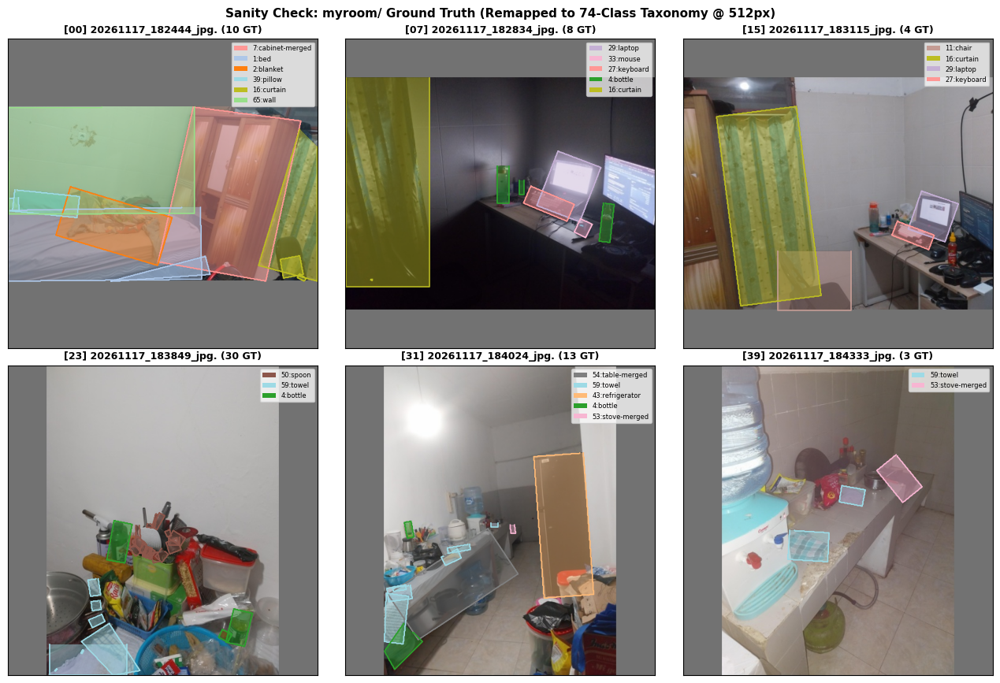

In [13]:
PALETTE = np.array(plt.get_cmap("tab20").colors)


def load_rgb(path: Path | str) -> np.ndarray:
    with Image.open(path) as im:
        return np.asarray(ImageOps.exif_transpose(im).convert("RGB"))


def masks_from_instances(instances, S: int):
    masks, labels = [], []
    for inst in instances:
        m = np.zeros((S, S), np.uint8)
        cv2.fillPoly(m, [np.round(inst["poly"]).astype(np.int32)], 1)
        if m.any():
            masks.append(m.astype(bool))
            labels.append(int(inst["cls"]))
    if masks:
        return np.stack(masks), np.array(labels, dtype=np.int64)
    return np.zeros((0, S, S), dtype=bool), np.zeros(0, dtype=np.int64)


def load_gt_for_eval(eval_set: PreparedEvalSet, idx: int):
    p = eval_set.images[idx]
    lbl_p = eval_set.labels_dir / f"{p.stem}.txt"
    insts = read_labels(lbl_p, eval_set.img_size, eval_set.img_size, class_map=None)
    return masks_from_instances(insts, eval_set.img_size)


def mask_bbox(mask: np.ndarray):
    ys, xs = np.where(mask > 0)
    if len(xs) == 0:
        return None
    return int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())


def draw_instances(
    ax,
    image: np.ndarray,
    masks,
    labels,
    scores=None,
    alpha: float = 0.45,
    title: str | None = None,
    legend: bool = True,
    show_boxes: bool = False,
    show_labels_on_mask: bool = False,
    show_scores: bool = True,
    max_legend: int = 12,
):
    ax.imshow(image)
    ax.set_xticks([])
    ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=9, fontweight="bold")

    seen = []
    scores_iter = scores if scores is not None else [None] * len(labels)
    for m, lab, sc in zip(masks, labels, scores_iter):
        m = np.asarray(m) > 0
        if m.sum() == 0:
            continue
        lab = int(lab)
        color = PALETTE[lab % len(PALETTE)]
        overlay = np.zeros((*m.shape, 4), np.float32)
        overlay[m] = (*color[:3], alpha)
        ax.imshow(overlay)

        cnts, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        for c in cnts:
            ax.plot(c[:, 0, 0], c[:, 0, 1], color=color, lw=1.2)

        box = mask_bbox(m)
        if box is not None:
            x1, y1, x2, y2 = box
            if show_boxes:
                ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, lw=1.1, ls="--"))
            if show_labels_on_mask:
                cname = CLASS_NAMES[lab] if lab < len(CLASS_NAMES) else str(lab)
                txt = f"{cname} {sc:.2f}" if (sc is not None and show_scores) else cname
                ax.text(
                    x1, max(4, y1 - 2), txt,
                    fontsize=6.5, color="white", fontweight="bold",
                    bbox=dict(facecolor=color, alpha=0.75, pad=1.0, edgecolor="none"),
                )
        seen.append(lab)

    if legend and seen:
        uniq = list(dict.fromkeys(seen))[:max_legend]
        handles = [
            Patch(facecolor=PALETTE[l % len(PALETTE)], label=f"{l}:{CLASS_NAMES[l]}" if l < len(CLASS_NAMES) else str(l))
            for l in uniq
        ]
        ax.legend(handles=handles, loc="upper right", fontsize=6, framealpha=0.75)


# Quick sanity check: display 6 ground-truth images from myroom (512px)
fig, axes = plt.subplots(2, 3, figsize=(13, 8.8))
sample_indices = np.linspace(0, len(EVAL_SET_512.images) - 1, 6, dtype=int)
for ax, idx in zip(axes.ravel(), sample_indices):
    p = EVAL_SET_512.images[idx]
    gt_m, gt_l = load_gt_for_eval(EVAL_SET_512, idx)
    draw_instances(ax, load_rgb(p), gt_m, gt_l, title=f"[{idx:02d}] {p.stem[:20]} ({len(gt_m)} GT)")
plt.suptitle("Sanity Check: myroom/ Ground Truth (Remapped to 74-Class Taxonomy @ 512px)", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig(OUT_DIR / "myroom_gt_sanity.png", dpi=140)
plt.show()

In [14]:
# ==============================================================================
# Model Loaders & Uniform Prediction Helpers
# ==============================================================================

def build_maskrcnn(num_classes: int, img_size: int = 512):
    # weights=None and weights_backbone=None prevent downloading pretrained weights before loading checkpoint
    model = maskrcnn_resnet50_fpn_v2(
        weights=None, weights_backbone=None, min_size=img_size, max_size=img_size
    )
    model.roi_heads.box_predictor = FastRCNNPredictor(
        model.roi_heads.box_predictor.cls_score.in_features, num_classes
    )
    model.roi_heads.mask_predictor = MaskRCNNPredictor(
        model.roi_heads.mask_predictor.conv5_mask.in_channels, 256, num_classes
    )
    return model


def load_model_bundle(model_key: str):
    """Load a model from MODEL_REGISTRY onto DEVICE."""
    cfg = MODEL_REGISTRY[model_key]
    arch = cfg["arch"]
    img_size = cfg["img_size"]
    path = cfg["path"]

    if arch == "yolo":
        model = YOLO(str(path))
        return {"key": model_key, "cfg": cfg, "model": model, "processor": None}

    if arch == "maskrcnn":
        ckpt = torch.load(path, map_location=DEVICE, weights_only=False)
        model = build_maskrcnn(NUM_CLASSES + 1, img_size=img_size).to(DEVICE)
        model.load_state_dict(ckpt["model"])
        model.eval()
        return {"key": model_key, "cfg": cfg, "model": model, "processor": None}

    if arch == "mask2former":
        model = Mask2FormerForUniversalSegmentation.from_pretrained(path).to(DEVICE).eval()
        proc_file = path / "preprocessor_config.json"
        if proc_file.is_file():
            processor = Mask2FormerImageProcessor.from_pretrained(path)
        else:
            processor = Mask2FormerImageProcessor(
                size={"height": img_size, "width": img_size}, ignore_index=255, reduce_labels=False
            )
        return {"key": model_key, "cfg": cfg, "model": model, "processor": processor}

    raise ValueError(f"Unknown arch: {arch}")


def unload_model_bundle(bundle: dict):
    model = bundle.get("model")
    if isinstance(model, torch.nn.Module):
        model.cpu()
    bundle.clear()
    free_gpu()


def _empty_pred(H: int, W: int):
    return {
        "masks": np.zeros((0, H, W), dtype=bool),
        "labels": np.zeros(0, dtype=np.int64),
        "scores": np.zeros(0, dtype=np.float32),
    }


def _yolo_predict_arrays(model, rgb_list: list[np.ndarray], img_size: int,
                         conf: float = 0.25, iou: float = 0.60, max_det: int = 100,
                         mask_thr: float = 0.50, batch_size: int | None = None):
    bs = batch_size or EVAL_BATCH_SIZE["yolo"]
    out = []
    dev = 0 if DEVICE.type == "cuda" else "cpu"
    for i in range(0, len(rgb_list), bs):
        # Ultralytics expects BGR numpy arrays when passing in-memory images
        chunk_bgr = [cv2.cvtColor(im, cv2.COLOR_RGB2BGR) for im in rgb_list[i:i + bs]]
        results = model.predict(
            chunk_bgr, imgsz=img_size, conf=conf, iou=iou, max_det=max_det,
            retina_masks=True, device=dev, verbose=False
        )
        for r, src_rgb in zip(results, rgb_list[i:i + bs]):
            H, W = src_rgb.shape[:2]
            if r.masks is None or len(r.masks) == 0:
                out.append(_empty_pred(H, W))
                continue
            masks_f = r.masks.data.cpu().numpy()
            masks = masks_f > mask_thr
            if masks.shape[1] != H or masks.shape[2] != W:
                masks = np.stack([
                    cv2.resize(m.astype(np.uint8), (W, H), interpolation=cv2.INTER_NEAREST).astype(bool)
                    for m in masks
                ])
            labels = r.boxes.cls.cpu().numpy().astype(np.int64)
            scores = r.boxes.conf.cpu().numpy().astype(np.float32)
            order = np.argsort(-scores)[:max_det]
            out.append({"masks": masks[order], "labels": labels[order], "scores": scores[order]})
    return out


@torch.no_grad()
def _maskrcnn_predict_arrays(model, rgb_list: list[np.ndarray],
                             score_thr: float = 0.50, mask_thr: float = 0.50,
                             max_det: int = 100, batch_size: int | None = None):
    model.to(DEVICE).eval()
    bs = batch_size or EVAL_BATCH_SIZE["maskrcnn"]
    t_mean = torch.from_numpy(MEAN)[:, None, None]
    t_std = torch.from_numpy(STD)[:, None, None]
    out = []
    for i in range(0, len(rgb_list), bs):
        xs = []
        shapes = []
        for im in rgb_list[i:i + bs]:
            shapes.append(im.shape[:2])
            x = torch.from_numpy(np.ascontiguousarray(im)).permute(2, 0, 1).float().div(255.0)
            xs.append(((x - t_mean) / t_std).to(DEVICE, non_blocking=USE_AMP))
        with amp_ctx():
            preds = model(xs)
        for pred, (H, W) in zip(preds, shapes):
            keep = torch.nonzero(pred["scores"] >= score_thr).squeeze(1)[:max_det]
            if keep.numel() == 0:
                out.append(_empty_pred(H, W))
                continue
            masks = (pred["masks"][keep, 0].cpu().numpy() > mask_thr)
            labels = pred["labels"][keep].cpu().numpy().astype(np.int64) - 1
            scores = pred["scores"][keep].cpu().numpy().astype(np.float32)
            order = np.argsort(-scores)[:max_det]
            out.append({"masks": masks[order], "labels": labels[order], "scores": scores[order]})
    return out


@torch.no_grad()
def _mask2former_predict_arrays(model, processor, rgb_list: list[np.ndarray],
                                score_thr: float = 0.50, mask_thr: float = 0.50,
                                max_det: int = 100, batch_size: int | None = None):
    model.to(DEVICE).eval()
    bs = batch_size or EVAL_BATCH_SIZE["mask2former"]
    t_mean = torch.from_numpy(MEAN)[:, None, None]
    t_std = torch.from_numpy(STD)[:, None, None]
    out = []
    for i in range(0, len(rgb_list), bs):
        xs = []
        target_sizes = []
        for im in rgb_list[i:i + bs]:
            H, W = im.shape[:2]
            target_sizes.append((H, W))
            x = torch.from_numpy(np.ascontiguousarray(im)).permute(2, 0, 1).float().div(255.0)
            xs.append((x - t_mean) / t_std)
        pv = torch.stack(xs).to(DEVICE, non_blocking=USE_AMP)
        with amp_ctx():
            outputs = model(pixel_values=pv)
        proc = processor.post_process_instance_segmentation(
            outputs,
            threshold=score_thr,
            mask_threshold=mask_thr,
            overlap_mask_area_threshold=0.8,
            target_sizes=target_sizes,
            return_binary_maps=True,
        )
        for d, (H, W) in zip(proc, target_sizes):
            seg = d["segmentation"]
            infos = d["segments_info"]
            if seg is None or len(infos) == 0:
                out.append(_empty_pred(H, W))
                continue
            seg_np = (seg.cpu().numpy() > 0.5)
            if seg_np.ndim == 2:
                # Fallback if HF returned a 2D segment-id map instead of binary stack
                masks = np.stack([seg_np == int(info["id"]) for info in infos])
            else:
                masks = seg_np[:len(infos)]
            labels = np.array([int(info.get("category_id", info.get("label_id"))) for info in infos], dtype=np.int64)
            scores = np.array([float(info["score"]) for info in infos], dtype=np.float32)
            order = np.argsort(-scores)[:max_det]
            out.append({"masks": masks[order], "labels": labels[order], "scores": scores[order]})
    return out


def predict_with_bundle(
    bundle: dict,
    rgb_list: list[np.ndarray],
    conf: float | None = None,
    mask_thr: float = 0.50,
    iou: float = 0.60,
    max_det: int = 100,
    batch_size: int | None = None,
):
    cfg = bundle["cfg"]
    arch = cfg["arch"]
    img_size = cfg["img_size"]
    if arch == "yolo":
        c = cfg["default_conf"] if conf is None else conf
        return _yolo_predict_arrays(
            bundle["model"], rgb_list, img_size=img_size,
            conf=c, iou=iou, max_det=max_det, mask_thr=mask_thr, batch_size=batch_size,
        )
    if arch == "maskrcnn":
        c = cfg["default_conf"] if conf is None else conf
        return _maskrcnn_predict_arrays(
            bundle["model"], rgb_list,
            score_thr=c, mask_thr=mask_thr, max_det=max_det, batch_size=batch_size,
        )
    if arch == "mask2former":
        c = cfg["default_conf"] if conf is None else conf
        return _mask2former_predict_arrays(
            bundle["model"], bundle["processor"], rgb_list,
            score_thr=c, mask_thr=mask_thr, max_det=max_det, batch_size=batch_size,
        )
    raise ValueError(f"Unsupported arch: {arch}")


def filter_pred(pred: dict, score_thr: float = 0.0, max_det: int = 100, class_ids=None) -> dict:
    keep = pred["scores"] >= score_thr
    if class_ids is not None:
        keep = keep & np.isin(pred["labels"], list(class_ids))
    idx = np.where(keep)[0][:max_det]
    return {
        "masks": pred["masks"][idx],
        "labels": pred["labels"][idx],
        "scores": pred["scores"][idx],
    }

In [15]:
# ==============================================================================
# COCO Evaluation, Per-Class AP & Prediction Caching Helpers
# ==============================================================================

def encode_rle(mask: np.ndarray) -> dict:
    rle = mask_utils.encode(np.asfortranarray((np.asarray(mask) > 0).astype(np.uint8)))
    if isinstance(rle["counts"], bytes):
        rle["counts"] = rle["counts"].decode("utf-8")
    return rle


def to_coco_results(preds: list[dict], eval_set: PreparedEvalSet) -> list[dict]:
    name2id = {item["file_name"]: item["id"] for item in eval_set.coco_dict["images"]}
    results = []
    for p, d in zip(eval_set.images, preds):
        img_id = name2id[p.name]
        for m, l, s in zip(d["masks"], d["labels"], d["scores"]):
            if m.sum() == 0:
                continue
            results.append({
                "image_id": img_id,
                "category_id": int(l) + 1,
                "segmentation": encode_rle(m),
                "score": float(s),
            })
    return results


def coco_results_to_preds(results: list[dict], eval_set: PreparedEvalSet) -> list[dict]:
    """Decode cached COCO JSON results back into per-image {masks, labels, scores}."""
    H = W = eval_set.img_size
    by_img = defaultdict(list)
    for r in results:
        by_img[r["image_id"]].append(r)

    out = []
    for item in eval_set.coco_dict["images"]:
        dets = sorted(by_img.get(item["id"], []), key=lambda x: -x["score"])
        if not dets:
            out.append(_empty_pred(H, W))
            continue
        masks = np.stack([mask_utils.decode(d["segmentation"]).astype(bool) for d in dets])
        labels = np.array([int(d["category_id"]) - 1 for d in dets], dtype=np.int64)
        scores = np.array([float(d["score"]) for d in dets], dtype=np.float32)
        out.append({"masks": masks, "labels": labels, "scores": scores})
    return out


def eval_coco_segm(coco_gt: COCO, results: list[dict], model_label: str, ms_per_img: float | None = None):
    if not results:
        row = {"model": model_label, "mAP@50-95": 0.0, "mAP@50": 0.0, "mAP@75": 0.0,
               "mAP_small": 0.0, "mAP_medium": 0.0, "mAP_large": 0.0, "AR@100": 0.0}
        if ms_per_img is not None:
            row["ms/img"] = ms_per_img
            row["FPS"] = 1000.0 / max(ms_per_img, 1e-6)
        return row, None

    dt = coco_gt.loadRes(results)
    ev = COCOeval(coco_gt, dt, "segm")
    ev.params.imgIds = sorted(coco_gt.getImgIds())
    ev.evaluate()
    ev.accumulate()
    with contextlib.redirect_stdout(io.StringIO()):
        ev.summarize()
    s = ev.stats
    row = {
        "model": model_label,
        "mAP@50-95": float(s[0]),
        "mAP@50": float(s[1]),
        "mAP@75": float(s[2]),
        "mAP_small": float(s[3]),
        "mAP_medium": float(s[4]),
        "mAP_large": float(s[5]),
        "AR@100": float(s[8]),
    }
    if ms_per_img is not None:
        row["ms/img"] = float(ms_per_img)
        row["FPS"] = float(1000.0 / max(ms_per_img, 1e-6))
    return row, ev


def extract_per_class_ap(ev: COCOeval, present_train_ids: list[int]) -> pd.DataFrame:
    """Extract AP@50-95 and AP@50 for every present class from an evaluated COCOeval object."""
    rows = []
    if ev is None:
        return pd.DataFrame(columns=["train_id", "class_name", "AP@50-95", "AP@50"])
    precision = ev.eval["precision"]  # [T, R, K, A, M]
    cat_ids = list(ev.params.catIds)
    for tid in present_train_ids:
        cid = tid + 1
        if cid not in cat_ids:
            continue
        k = cat_ids.index(cid)
        p_all = precision[:, :, k, 0, 2]   # all IoU thresholds, area=all, maxDet=100
        p_50 = precision[0, :, k, 0, 2]    # IoU=0.50, area=all, maxDet=100
        ap_all = float(np.mean(p_all[p_all > -1])) if np.any(p_all > -1) else np.nan
        ap_50 = float(np.mean(p_50[p_50 > -1])) if np.any(p_50 > -1) else np.nan
        rows.append({
            "train_id": tid,
            "class_name": CLASS_NAMES[tid],
            "AP@50-95": ap_all,
            "AP@50": ap_50,
        })
    return pd.DataFrame(rows)


def run_eval_suite(model_keys: list[str], eval_set: PreparedEvalSet, save_dir: Path, force_rerun: bool = False):
    """Run full inference & COCO evaluation for a list of models, caching predictions to disk."""
    rgb_imgs = [load_rgb(p) for p in eval_set.images]
    coco_gt = COCO(str(eval_set.coco_path))
    preds_dir = save_dir / "preds"
    preds_dir.mkdir(parents=True, exist_ok=True)

    all_preds = {}
    all_coco_res = {}
    all_coco_evals = {}
    metric_rows = []
    per_class_ap50 = {}
    per_class_ap = {}

    for key in model_keys:
        cfg = MODEL_REGISTRY[key]
        arch = cfg["arch"]
        label = cfg["label"]
        pred_file = preds_dir / f"{key}.json"
        time_file = preds_dir / f"{key}_timing.json"

        if pred_file.is_file() and not force_rerun:
            coco_res = json.loads(pred_file.read_text(encoding="utf-8"))
            preds = coco_results_to_preds(coco_res, eval_set)
            ms_per_img = json.loads(time_file.read_text(encoding="utf-8")).get("ms_per_img") if time_file.is_file() else None
            print(f"[cached] {label:<24s}: {len(coco_res):5d} detections")
        else:
            bundle = load_model_bundle(key)
            kw = COCO_EVAL_THR[arch]
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            t0 = time.perf_counter()
            preds = predict_with_bundle(
                bundle,
                rgb_imgs,
                conf=kw.get("conf", kw.get("score_thr")),
                mask_thr=kw.get("mask_thr", 0.50),
                iou=kw.get("iou", 0.60),
                max_det=kw.get("max_det", 100),
            )
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            elapsed_ms = (time.perf_counter() - t0) * 1000.0
            ms_per_img = elapsed_ms / max(len(rgb_imgs), 1)
            unload_model_bundle(bundle)

            coco_res = to_coco_results(preds, eval_set)
            pred_file.write_text(json.dumps(coco_res), encoding="utf-8")
            time_file.write_text(json.dumps({"ms_per_img": ms_per_img, "n_images": len(rgb_imgs)}), encoding="utf-8")
            print(f"[run]    {label:<24s}: {len(coco_res):5d} detections | {ms_per_img:6.1f} ms/img ({1000.0 / ms_per_img:5.1f} FPS)")

        row, ev = eval_coco_segm(coco_gt, coco_res, label, ms_per_img=ms_per_img)
        metric_rows.append(row)
        all_preds[key] = preds
        all_coco_res[key] = coco_res
        all_coco_evals[key] = ev

        pc_df = extract_per_class_ap(ev, MYROOM_PRESENT_TRAIN_IDS)
        per_class_ap50[label] = pc_df.set_index("class_name")["AP@50"]
        per_class_ap[label] = pc_df.set_index("class_name")["AP@50-95"]

    metrics_df = pd.DataFrame(metric_rows).set_index("model")
    metrics_df.to_csv(save_dir / "metrics_myroom.csv")

    ap50_df = pd.DataFrame(per_class_ap50)
    ap50_df["gt_instances"] = [mapped_counts[TRAIN_NAME_TO_ID[c]] for c in ap50_df.index]
    ap50_df = ap50_df.sort_values("gt_instances", ascending=False)
    ap50_df.to_csv(save_dir / "per_class_ap50_myroom.csv")

    ap_all_df = pd.DataFrame(per_class_ap)
    ap_all_df["gt_instances"] = [mapped_counts[TRAIN_NAME_TO_ID[c]] for c in ap_all_df.index]
    ap_all_df = ap_all_df.sort_values("gt_instances", ascending=False)
    ap_all_df.to_csv(save_dir / "per_class_ap50_95_myroom.csv")

    return {
        "eval_set": eval_set,
        "coco_gt": coco_gt,
        "preds": all_preds,
        "coco_res": all_coco_res,
        "coco_evals": all_coco_evals,
        "metrics": metrics_df,
        "per_class_ap50": ap50_df,
        "per_class_ap": ap_all_df,
    }


def build_domain_shift_table(orig_csv: Path, myroom_metrics: pd.DataFrame, orig_index_col: str) -> pd.DataFrame | None:
    if not orig_csv.is_file():
        return None
    orig = pd.read_csv(orig_csv).set_index(orig_index_col)
    rows = []
    for model_name in myroom_metrics.index:
        if model_name not in orig.index:
            continue
        for metric in ("mAP@50-95", "mAP@50", "mAP@75", "AR@100"):
            v_orig = float(orig.loc[model_name, metric])
            v_room = float(myroom_metrics.loc[model_name, metric])
            delta = v_room - v_orig
            rel_pct = (delta / v_orig * 100.0) if v_orig > 1e-9 else np.nan
            rows.append({
                "model": model_name,
                "metric": metric,
                "orig_val": v_orig,
                "myroom": v_room,
                "delta": delta,
                "delta_%": rel_pct,
            })
    return pd.DataFrame(rows)

## 4. PART 1 — Model Comparison on `myroom/` (`512 × 512`)

Evaluates the 3 architecture families from `content/outputs/`:
1. **YOLO11n-seg** (one-stage, anchor-free + ProtoNet 1/4-res prototype masks)
2. **Mask R-CNN (ResNet-50-FPN v2)** (two-stage RPN → RoIAlign → 28×28 mask head)
3. **Mask2Former (Swin-Tiny)** (transformer query-based masked attention)

Set `FORCE_RERUN_PART1 = True` if you want to recompute predictions from scratch instead of loading cached JSONs.

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
[run]    YOLO11n-seg             :  3977 detections |   45.9 ms/img ( 21.8 FPS)
Loading and preparing results...
DONE (t=0.05s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=0.22s).
Accumulating evaluation results...
DONE (t=0.13s).
[run]    Mask R-CNN (R50-FPN)    :  3554 detections |  108.6 ms/img (  9.2 FPS)
Loading and preparing results...
DONE (t=0.05s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=0.21s).
Accumulating evaluation results...
DONE (t=0.14s).


Loading weights:   0%|          | 0/556 [00:00<?, ?it/s]

[run]    Mask2Former (Swin-T)    :  3935 detections |  122.0 ms/img (  8.2 FPS)
Loading and preparing results...
DONE (t=0.05s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=0.23s).
Accumulating evaluation results...
DONE (t=0.14s).

=== PART 1: COCO Mask Metrics on myroom/ (40 images @ 512px) ===


,mAP@50-95,mAP@50,mAP@75,mAP_small,mAP_medium,mAP_large,AR@100,ms/img,FPS
model,,,,,,,,,
YOLO11n-seg,0.0556,0.1462,0.0465,0.0891,0.0673,0.1024,0.1196,45.8569,21.8070
Mask R-CNN (R50-FPN),0.0740,0.1653,0.0595,0.0349,0.0659,0.1867,0.1707,108.6207,9.2063
Mask2Former (Swin-T),0.0728,0.1577,0.0615,0.0361,0.0549,0.1683,0.1739,122.0195,8.1954


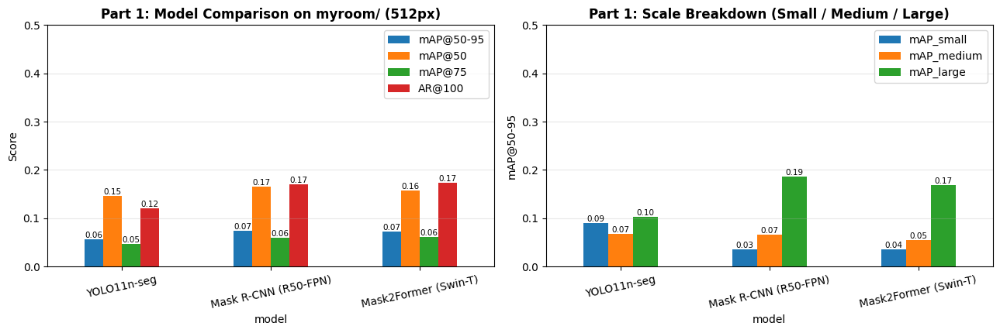

In [ ]:
FORCE_RERUN_PART1 = True  # Recompute after orientation fix (set back to False once cached)

PART1_DIR = OUT_DIR / "part1_models"
PART1 = run_eval_suite(PART1_KEYS, EVAL_SET_512, PART1_DIR, force_rerun=FORCE_RERUN_PART1)

pd.set_option("display.float_format", lambda v: f"{v:.4f}")
print("\n=== PART 1: COCO Mask Metrics on myroom/ (40 images @ 512px) ===")
display(PART1["metrics"])

# Bar chart: main COCO metrics
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
PART1["metrics"][["mAP@50-95", "mAP@50", "mAP@75", "AR@100"]].plot.bar(
    ax=axes[0], rot=12, ylim=(0, max(0.5, float(PART1["metrics"]["mAP@50"].max()) * 1.25))
)
axes[0].set_title("Part 1: Model Comparison on myroom/ (512px)", fontweight="bold")
axes[0].set_ylabel("Score")
axes[0].grid(axis="y", alpha=0.3)
for p in axes[0].patches:
    h = p.get_height()
    if h > 0:
        axes[0].annotate(f"{h:.2f}", (p.get_x() + p.get_width() / 2, h),
                         ha="center", va="bottom", fontsize=7.5)

PART1["metrics"][["mAP_small", "mAP_medium", "mAP_large"]].plot.bar(
    ax=axes[1], rot=12, ylim=(0, max(0.5, float(PART1["metrics"][["mAP_small", "mAP_medium", "mAP_large"]].max().max()) * 1.25))
)
axes[1].set_title("Part 1: Scale Breakdown (Small / Medium / Large)", fontweight="bold")
axes[1].set_ylabel("mAP@50-95")
axes[1].grid(axis="y", alpha=0.3)
for p in axes[1].patches:
    h = p.get_height()
    if h > 0:
        axes[1].annotate(f"{h:.2f}", (p.get_x() + p.get_width() / 2, h),
                         ha="center", va="bottom", fontsize=7.5)

plt.tight_layout()
plt.savefig(PART1_DIR / "metrics_part1_myroom.png", dpi=150)
plt.show()

=== PART 1: Domain Shift (Original Dataset Val vs Self-Collected myroom/) ===


,model,metric,orig_val,myroom,delta,delta_%
0,YOLO11n-seg,mAP@50-95,0.1069,0.0556,-0.0513,-48.0173
1,YOLO11n-seg,mAP@50,0.2265,0.1462,-0.0803,-35.4388
2,YOLO11n-seg,mAP@75,0.0946,0.0465,-0.0482,-50.9052
3,YOLO11n-seg,AR@100,0.1993,0.1196,-0.0798,-40.0148
4,Mask R-CNN (R50-FPN),mAP@50-95,0.1174,0.0740,-0.0434,-36.9961
5,Mask R-CNN (R50-FPN),mAP@50,0.2156,0.1653,-0.0502,-23.3065
6,Mask R-CNN (R50-FPN),mAP@75,0.1193,0.0595,-0.0597,-50.0775
7,Mask R-CNN (R50-FPN),AR@100,0.2104,0.1707,-0.0396,-18.8449
8,Mask2Former (Swin-T),mAP@50-95,0.1485,0.0728,-0.0757,-50.9719
9,Mask2Former (Swin-T),mAP@50,0.2663,0.1577,-0.1087,-40.8051


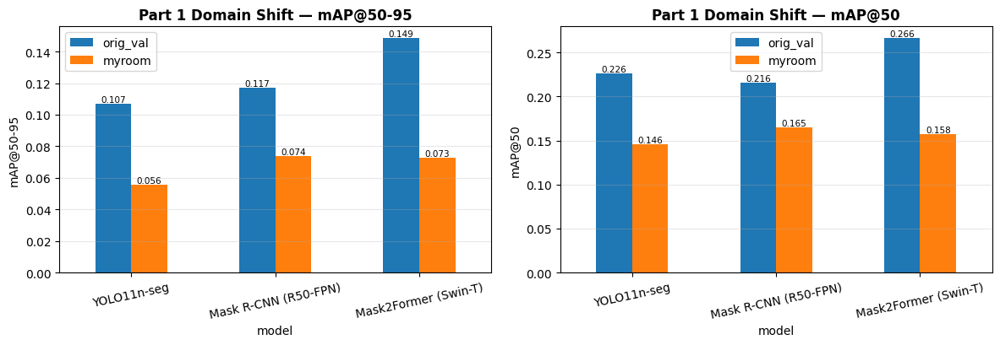


=== PART 1: Per-Class AP@50 on myroom/ ===


,YOLO11n-seg,Mask R-CNN (R50-FPN),Mask2Former (Swin-T),gt_instances
class_name,,,,
spoon,0.0320,0.0173,0.0561,49
towel,0.0059,0.0000,0.0000,41
table-merged,0.0527,0.1111,0.0454,23
bottle,0.2733,0.2531,0.1353,22
bed,0.2673,0.5982,0.3748,22
curtain,0.0000,0.0000,0.0693,20
pillow,0.7496,0.7261,0.7088,18
cabinet-merged,0.1601,0.6794,0.3472,16
pan,0.5917,0.4784,0.4923,15


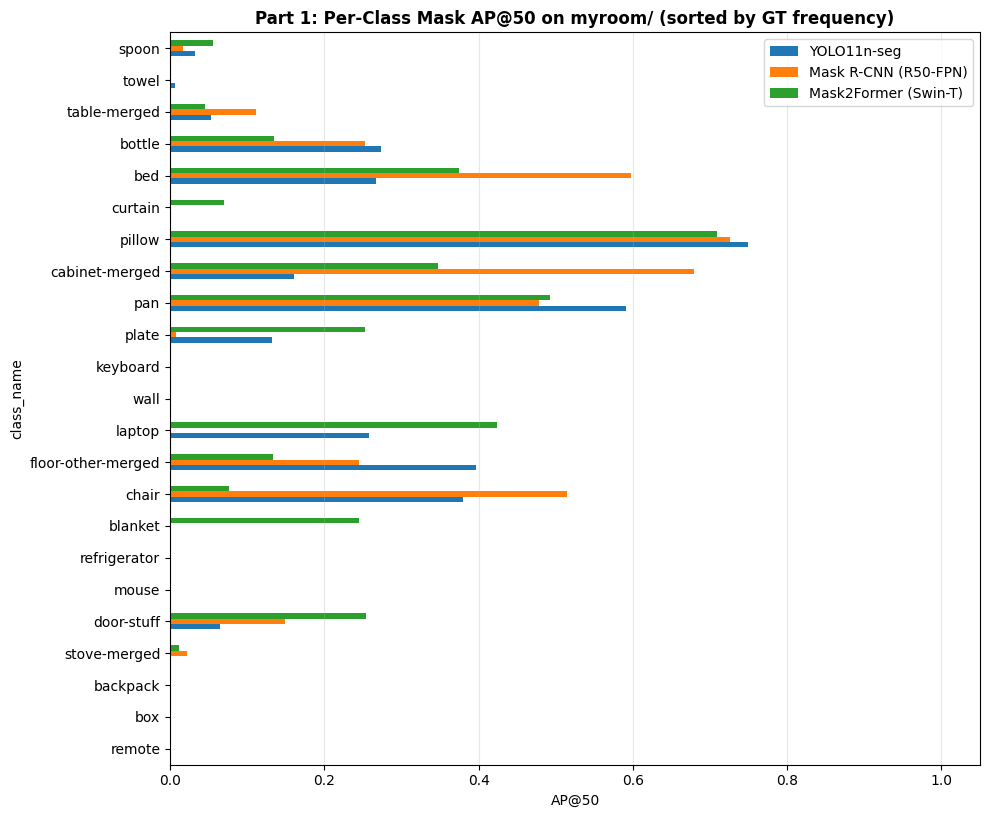

In [ ]:
# Part 1: Domain Shift (Original Val Set vs myroom/ Test Set) & Per-Class AP@50
shift_p1 = build_domain_shift_table(ORIG_METRICS_PART1, PART1["metrics"], orig_index_col="model")
if shift_p1 is not None:
    shift_p1.to_csv(PART1_DIR / "domain_shift_part1.csv", index=False)
    print("=== PART 1: Domain Shift (Original Dataset Val vs Self-Collected myroom/) ===")
    display(shift_p1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for ax, metric in zip(axes, ("mAP@50-95", "mAP@50")):
        sub = shift_p1[shift_p1["metric"] == metric].set_index("model")[["orig_val", "myroom"]]
        sub.plot.bar(ax=ax, rot=12)
        ax.set_title(f"Part 1 Domain Shift — {metric}", fontweight="bold")
        ax.set_ylabel(metric)
        ax.grid(axis="y", alpha=0.3)
        for p in ax.patches:
            h = p.get_height()
            if h > 0:
                ax.annotate(f"{h:.3f}", (p.get_x() + p.get_width() / 2, h),
                            ha="center", va="bottom", fontsize=7.5)
    plt.tight_layout()
    plt.savefig(PART1_DIR / "domain_shift_part1.png", dpi=150)
    plt.show()

print("\n=== PART 1: Per-Class AP@50 on myroom/ ===")
display(PART1["per_class_ap50"])

# Horizontal bar chart of per-class AP@50
ap_plot_df = PART1["per_class_ap50"].drop(columns=["gt_instances"]).iloc[::-1]
ax = ap_plot_df.plot.barh(figsize=(10, max(5, 0.36 * len(ap_plot_df))))
ax.set_title("Part 1: Per-Class Mask AP@50 on myroom/ (sorted by GT frequency)", fontweight="bold")
ax.set_xlabel("AP@50")
ax.set_xlim(0, 1.05)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(PART1_DIR / "per_class_ap50_part1.png", dpi=150)
plt.show()

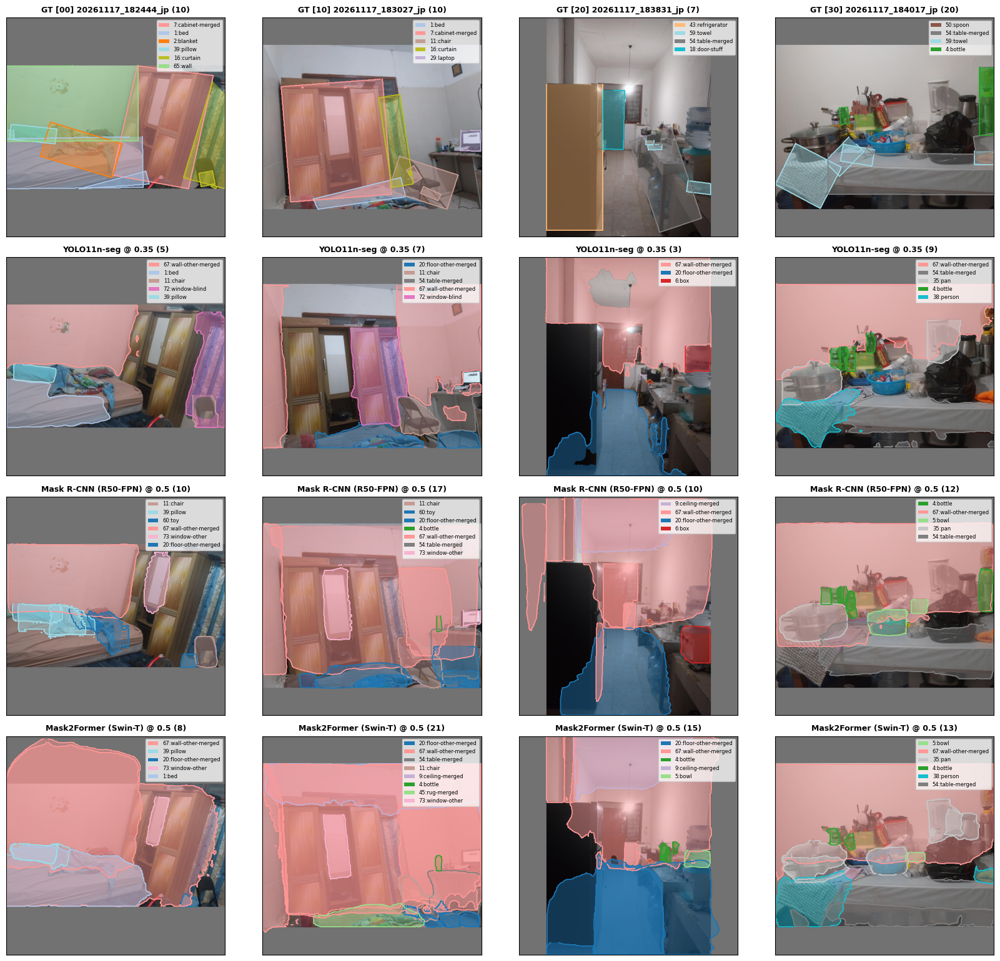

In [ ]:
# Part 1: Qualitative Side-by-Side Overview (4 sample myroom photos)
PART1_PREVIEW_INDICES = [0, 10, 20, 30]

fig, axes = plt.subplots(4, len(PART1_PREVIEW_INDICES), figsize=(4.2 * len(PART1_PREVIEW_INDICES), 15.5))
for col, idx in enumerate(PART1_PREVIEW_INDICES):
    p = EVAL_SET_512.images[idx]
    img = load_rgb(p)
    gt_m, gt_l = load_gt_for_eval(EVAL_SET_512, idx)
    draw_instances(axes[0, col], img, gt_m, gt_l, title=f"GT [{idx:02d}] {p.stem[:18]} ({len(gt_m)})")
    for row_i, key in enumerate(PART1_KEYS, start=1):
        cfg = MODEL_REGISTRY[key]
        pred = filter_pred(PART1["preds"][key][idx], score_thr=cfg["default_conf"], max_det=25)
        draw_instances(
            axes[row_i, col], img, pred["masks"], pred["labels"], pred["scores"],
            title=f"{cfg['label']} @ {cfg['default_conf']} ({len(pred['masks'])})"
        )
plt.tight_layout()
plt.savefig(PART1_DIR / "qualitative_part1_overview.png", dpi=140)
plt.show()

## 5. PART 2 — Augmentation Comparison on `myroom/` (`640 × 640`)

Evaluates the 3 **Mask2Former (Swin-T)** augmentation checkpoints from `content/outputs_augmentation/`:
1. **Mask2Former (No Aug)** — baseline without training augmentation
2. **Mask2Former (Aug 1)** — light geometric + lighting jitter
3. **Mask2Former (Aug 2)** — heavy geometric, blur/noise & color jitter

Set `FORCE_RERUN_PART2 = True` if you want to recompute predictions from scratch instead of loading cached JSONs.

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!


Loading weights:   0%|          | 0/556 [00:00<?, ?it/s]

[run]    Mask2Former (No Aug)    :  3986 detections |  171.1 ms/img (  5.8 FPS)
Loading and preparing results...
DONE (t=0.07s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=0.25s).
Accumulating evaluation results...
DONE (t=0.13s).


Loading weights:   0%|          | 0/556 [00:00<?, ?it/s]

[run]    Mask2Former (Aug 1)     :  3954 detections |  186.1 ms/img (  5.4 FPS)
Loading and preparing results...
DONE (t=0.06s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=0.22s).
Accumulating evaluation results...
DONE (t=0.13s).


Loading weights:   0%|          | 0/556 [00:00<?, ?it/s]

[run]    Mask2Former (Aug 2)     :  3901 detections |  253.0 ms/img (  4.0 FPS)
Loading and preparing results...
DONE (t=0.06s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=0.23s).
Accumulating evaluation results...
DONE (t=0.14s).

=== PART 2: COCO Mask Metrics on myroom/ (40 images @ 640px) ===


,mAP@50-95,mAP@50,mAP@75,mAP_small,mAP_medium,mAP_large,AR@100,ms/img,FPS
model,,,,,,,,,
Mask2Former (No Aug),0.0890,0.2063,0.0764,0.0498,0.0681,0.1684,0.2160,171.0552,5.8461
Mask2Former (Aug 1),0.0895,0.2073,0.0633,0.0377,0.0875,0.1613,0.1807,186.0867,5.3738
Mask2Former (Aug 2),0.0958,0.2257,0.0771,0.0621,0.1016,0.1636,0.2067,252.9957,3.9526


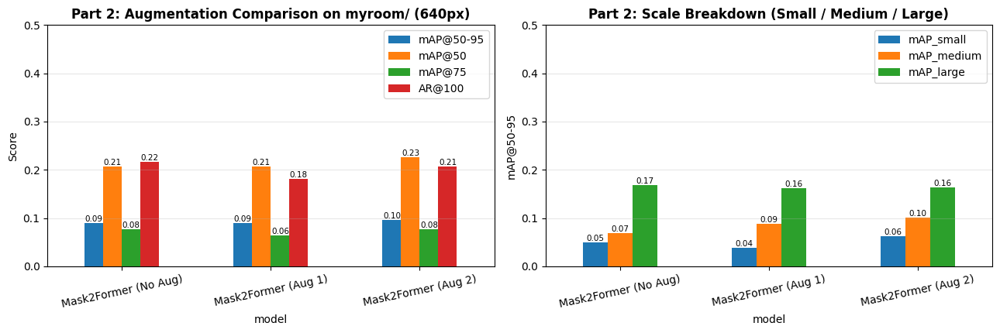

In [ ]:
FORCE_RERUN_PART2 = True  # Recompute after orientation fix (set back to False once cached)

PART2_DIR = OUT_DIR / "part2_augmentation"
PART2 = run_eval_suite(PART2_KEYS, EVAL_SET_640, PART2_DIR, force_rerun=FORCE_RERUN_PART2)

print("\n=== PART 2: COCO Mask Metrics on myroom/ (40 images @ 640px) ===")
display(PART2["metrics"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
PART2["metrics"][["mAP@50-95", "mAP@50", "mAP@75", "AR@100"]].plot.bar(
    ax=axes[0], rot=12, ylim=(0, max(0.5, float(PART2["metrics"]["mAP@50"].max()) * 1.25))
)
axes[0].set_title("Part 2: Augmentation Comparison on myroom/ (640px)", fontweight="bold")
axes[0].set_ylabel("Score")
axes[0].grid(axis="y", alpha=0.3)
for p in axes[0].patches:
    h = p.get_height()
    if h > 0:
        axes[0].annotate(f"{h:.2f}", (p.get_x() + p.get_width() / 2, h),
                         ha="center", va="bottom", fontsize=7.5)

PART2["metrics"][["mAP_small", "mAP_medium", "mAP_large"]].plot.bar(
    ax=axes[1], rot=12, ylim=(0, max(0.5, float(PART2["metrics"][["mAP_small", "mAP_medium", "mAP_large"]].max().max()) * 1.25))
)
axes[1].set_title("Part 2: Scale Breakdown (Small / Medium / Large)", fontweight="bold")
axes[1].set_ylabel("mAP@50-95")
axes[1].grid(axis="y", alpha=0.3)
for p in axes[1].patches:
    h = p.get_height()
    if h > 0:
        axes[1].annotate(f"{h:.2f}", (p.get_x() + p.get_width() / 2, h),
                         ha="center", va="bottom", fontsize=7.5)

plt.tight_layout()
plt.savefig(PART2_DIR / "metrics_part2_myroom.png", dpi=150)
plt.show()

=== PART 2: Domain Shift (Original Dataset Val vs Self-Collected myroom/) ===


,model,metric,orig_val,myroom,delta,delta_%
0,Mask2Former (No Aug),mAP@50-95,0.1537,0.0890,-0.0647,-42.1159
1,Mask2Former (No Aug),mAP@50,0.2970,0.2063,-0.0907,-30.5361
2,Mask2Former (No Aug),mAP@75,0.1306,0.0764,-0.0542,-41.4837
3,Mask2Former (No Aug),AR@100,0.2807,0.2160,-0.0647,-23.0582
4,Mask2Former (Aug 1),mAP@50-95,0.1538,0.0895,-0.0644,-41.8439
5,Mask2Former (Aug 1),mAP@50,0.2913,0.2073,-0.0840,-28.8286
6,Mask2Former (Aug 1),mAP@75,0.1395,0.0633,-0.0762,-54.6526
7,Mask2Former (Aug 1),AR@100,0.2602,0.1807,-0.0795,-30.5497
8,Mask2Former (Aug 2),mAP@50-95,0.2108,0.0958,-0.1150,-54.5438
9,Mask2Former (Aug 2),mAP@50,0.3719,0.2257,-0.1462,-39.3093


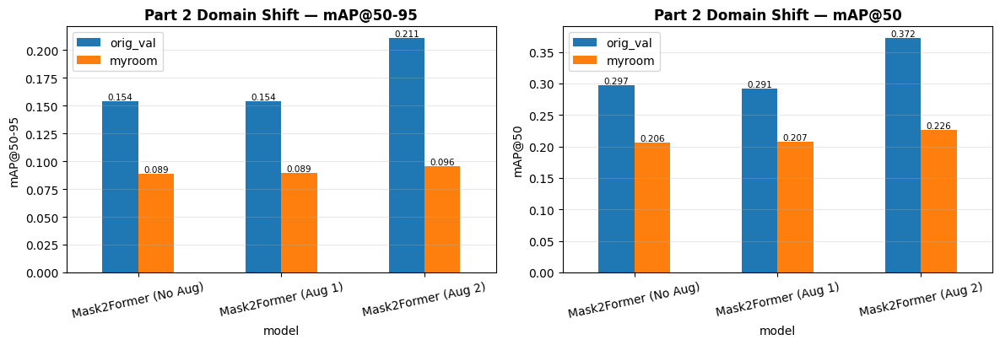


=== PART 2: Per-Class AP@50 on myroom/ ===


,Mask2Former (No Aug),Mask2Former (Aug 1),Mask2Former (Aug 2),gt_instances
class_name,,,,
spoon,0.1471,0.0764,0.0995,49
towel,0.0000,0.0000,0.0986,41
table-merged,0.0267,0.0445,0.0111,23
bottle,0.3425,0.3084,0.2491,22
bed,0.5168,0.3815,0.4617,22
curtain,0.0000,0.0000,0.1568,20
pillow,0.3560,0.6791,0.8565,18
cabinet-merged,0.1538,0.2928,0.3328,16
pan,0.3584,0.7034,0.4233,15


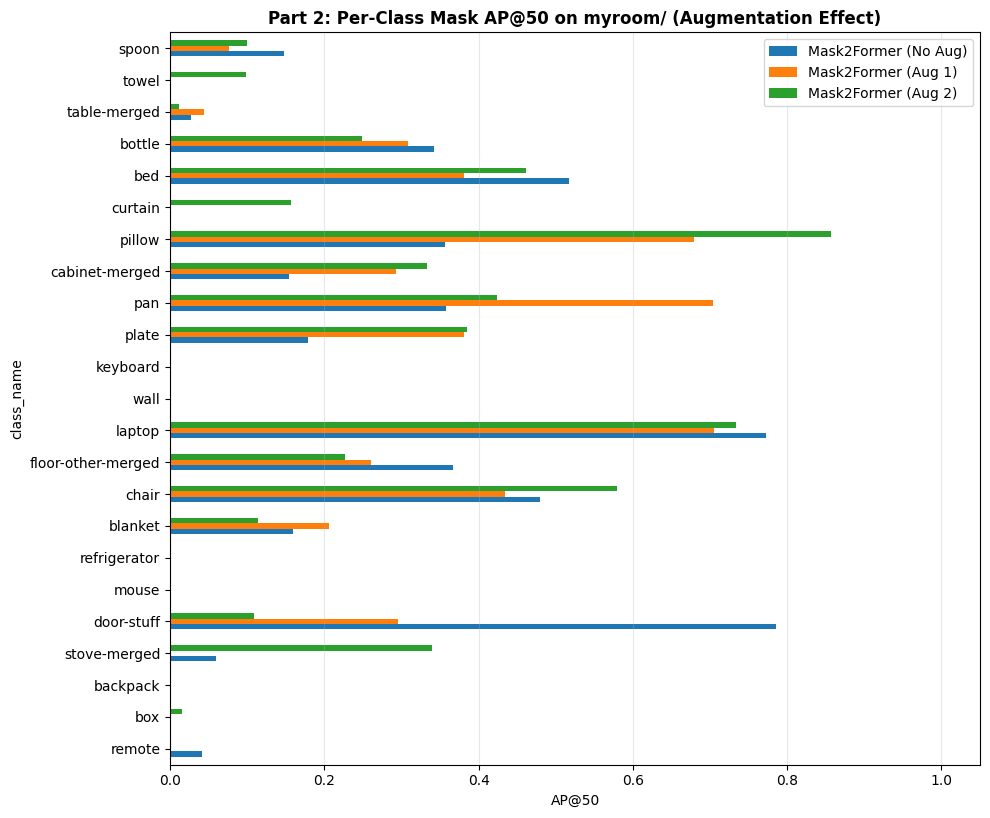

In [ ]:
# Part 2: Domain Shift (Original Val Set vs myroom/ Test Set) & Per-Class AP@50
shift_p2 = build_domain_shift_table(ORIG_METRICS_PART2, PART2["metrics"], orig_index_col="experiment")
if shift_p2 is not None:
    shift_p2.to_csv(PART2_DIR / "domain_shift_part2.csv", index=False)
    print("=== PART 2: Domain Shift (Original Dataset Val vs Self-Collected myroom/) ===")
    display(shift_p2)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for ax, metric in zip(axes, ("mAP@50-95", "mAP@50")):
        sub = shift_p2[shift_p2["metric"] == metric].set_index("model")[["orig_val", "myroom"]]
        sub.plot.bar(ax=ax, rot=12)
        ax.set_title(f"Part 2 Domain Shift — {metric}", fontweight="bold")
        ax.set_ylabel(metric)
        ax.grid(axis="y", alpha=0.3)
        for p in ax.patches:
            h = p.get_height()
            if h > 0:
                ax.annotate(f"{h:.3f}", (p.get_x() + p.get_width() / 2, h),
                            ha="center", va="bottom", fontsize=7.5)
    plt.tight_layout()
    plt.savefig(PART2_DIR / "domain_shift_part2.png", dpi=150)
    plt.show()

print("\n=== PART 2: Per-Class AP@50 on myroom/ ===")
display(PART2["per_class_ap50"])

ap2_plot_df = PART2["per_class_ap50"].drop(columns=["gt_instances"]).iloc[::-1]
ax = ap2_plot_df.plot.barh(figsize=(10, max(5, 0.36 * len(ap2_plot_df))))
ax.set_title("Part 2: Per-Class Mask AP@50 on myroom/ (Augmentation Effect)", fontweight="bold")
ax.set_xlabel("AP@50")
ax.set_xlim(0, 1.05)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(PART2_DIR / "per_class_ap50_part2.png", dpi=150)
plt.show()

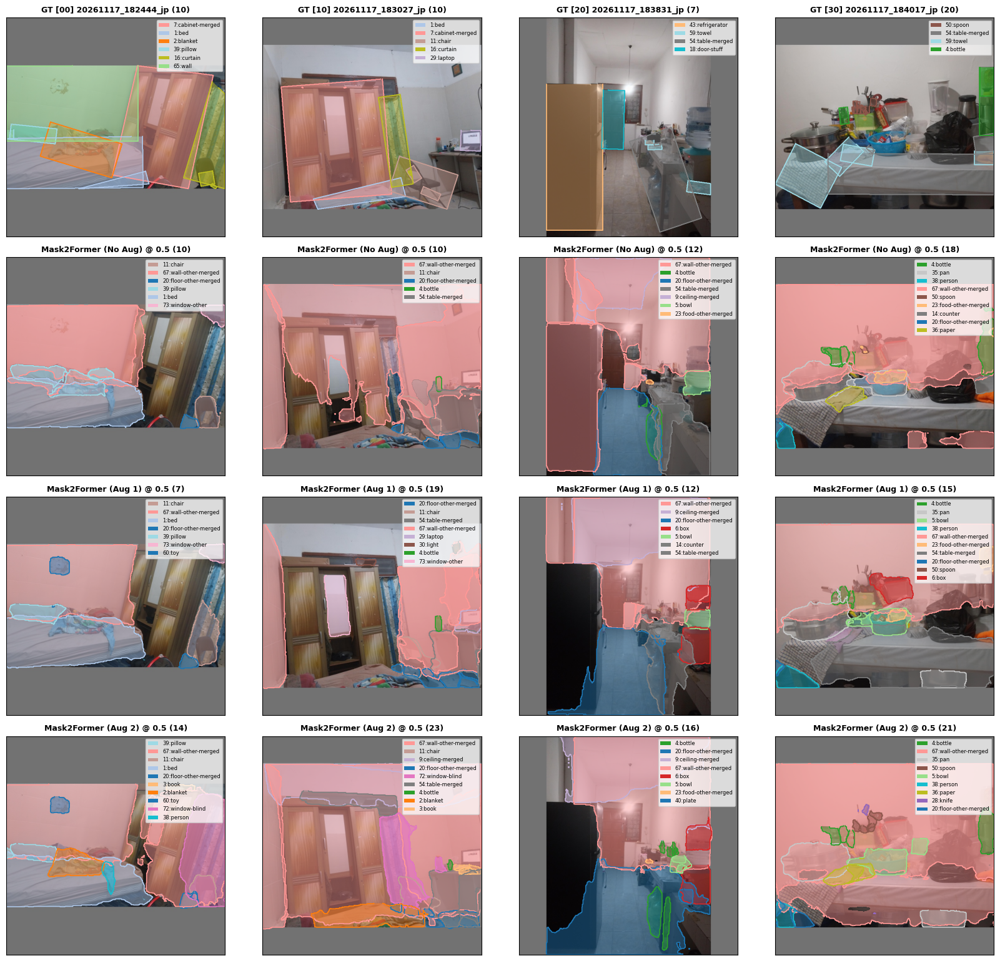

In [ ]:
# Part 2: Qualitative Side-by-Side Overview (same 4 sample myroom photos)
PART2_PREVIEW_INDICES = PART1_PREVIEW_INDICES

fig, axes = plt.subplots(4, len(PART2_PREVIEW_INDICES), figsize=(4.2 * len(PART2_PREVIEW_INDICES), 15.5))
for col, idx in enumerate(PART2_PREVIEW_INDICES):
    p = EVAL_SET_640.images[idx]
    img = load_rgb(p)
    gt_m, gt_l = load_gt_for_eval(EVAL_SET_640, idx)
    draw_instances(axes[0, col], img, gt_m, gt_l, title=f"GT [{idx:02d}] {p.stem[:18]} ({len(gt_m)})")
    for row_i, key in enumerate(PART2_KEYS, start=1):
        cfg = MODEL_REGISTRY[key]
        pred = filter_pred(PART2["preds"][key][idx], score_thr=cfg["default_conf"], max_det=25)
        draw_instances(
            axes[row_i, col], img, pred["masks"], pred["labels"], pred["scores"],
            title=f"{cfg['label']} @ {cfg['default_conf']} ({len(pred['masks'])})"
        )
plt.tight_layout()
plt.savefig(PART2_DIR / "qualitative_part2_overview.png", dpi=140)
plt.show()

## 6. Task 4 — Evidence-Based Failure Analysis (2 Parts: Best of Part 1 & Best of Part 2)

Designed for **Component 4**:
> *"Pilih 5 foto dari test set sendiri di mana model gagal (tidak terdeteksi, mask bocor, salah kelas, objek terpecah). Jelaskan penyebab dan kaitkan dengan mekanisme model (misalnya resolusi prototype mask YOLO, grid 28×28 Mask R-CNN). Uji penjelasan dengan satu eksperimen kecil."*

### 6.1 Best Model Selection & Full 40-Image Failure Audit
1. Automatically picks the **best model from Part 1** (`BEST_PART1_KEY`) and the **best model from Part 2** (`BEST_PART2_KEY`) based on `BEST_SELECTION_METRIC` (`"mAP@50-95"` on `myroom/`). You can override either key manually if desired.
2. Audits every one of the 40 `myroom/` test photos against GT masks for:
   - **`missed` (Tidak Terdeteksi / FN)**: GT object with no same-class match (IoU ≥ `0.50`).
   - **`wrong_class` (Salah Kelas)**: Prediction overlapping a GT mask (IoU ≥ `0.30`) with the wrong class label.
   - **`mask_leak` (Mask Bocor)**: Matched same-class mask where > `30%` of predicted area spills outside GT.
   - **`split_obj` (Objek Terpecah)**: ≥ 2 same-class predictions overlapping the same GT object.

Best Part 1 Model (by mAP@50-95): Mask R-CNN (R50-FPN)  [key='maskrcnn', 512px]
  mAP@50-95=0.0740 | mAP@50=0.1653 | AR@100=0.1707
Best Part 2 Model (by mAP@50-95): Mask2Former (Aug 2)  [key='m2f_aug_2', 640px]
  mAP@50-95=0.0958 | mAP@50=0.2257 | AR@100=0.2067

=== Task 4 Summary: Best Model from Part 1 vs Best Model from Part 2 (All 40 myroom/ Photos) ===


,Model,mAP@50-95,mAP@50,Total_GT,TP,Missed,WrongCls,MaskLeak,Split,Mean_F1
Part,,,,,,,,,,
"Task 4 — Part A (Best of Part 1, 512px)",Mask R-CNN (R50-FPN),0.0740,0.1653,306,45,261,39,9,17,0.1506
"Task 4 — Part B (Best of Part 2, 640px)",Mask2Former (Aug 2),0.0958,0.2257,308,77,231,45,36,35,0.2023


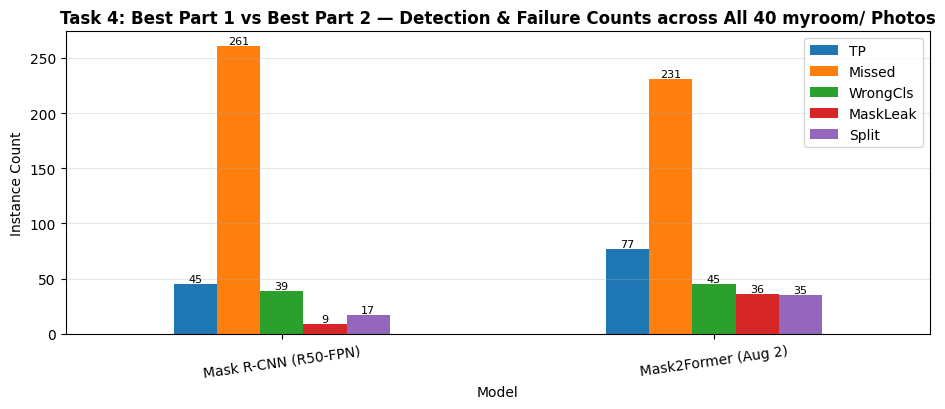

In [ ]:
FAIL_DIR = OUT_DIR / "failure_analysis"
(FAIL_DIR / "part1_best_all40").mkdir(parents=True, exist_ok=True)
(FAIL_DIR / "part2_best_all40").mkdir(parents=True, exist_ok=True)

# Selection rule for best model from Part 1 & Part 2
BEST_SELECTION_METRIC = "mAP@50-95"   # e.g. "mAP@50-95" | "mAP@50" | "AR@100"
BEST_PART1_KEY_OVERRIDE = None        # e.g. "yolo" | "maskrcnn" | "mask2former" | None (auto)
BEST_PART2_KEY_OVERRIDE = None        # e.g. "m2f_no_aug" | "m2f_aug_1" | "m2f_aug_2" | None (auto)


def pick_best_model_key(suite: dict, model_keys: list[str], metric: str = "mAP@50-95", override: str | None = None) -> str:
    if override is not None:
        if override not in model_keys:
            raise ValueError(f"Override '{override}' not in {model_keys}")
        return override
    label_to_key = {MODEL_REGISTRY[k]["label"]: k for k in model_keys}
    best_label = suite["metrics"][metric].idxmax()
    return label_to_key[best_label]


BEST_PART1_KEY = pick_best_model_key(PART1, PART1_KEYS, BEST_SELECTION_METRIC, BEST_PART1_KEY_OVERRIDE)
BEST_PART2_KEY = pick_best_model_key(PART2, PART2_KEYS, BEST_SELECTION_METRIC, BEST_PART2_KEY_OVERRIDE)

BEST_PART1_LABEL = MODEL_REGISTRY[BEST_PART1_KEY]["label"]
BEST_PART2_LABEL = MODEL_REGISTRY[BEST_PART2_KEY]["label"]

print(f"Best Part 1 Model (by {BEST_SELECTION_METRIC}): {BEST_PART1_LABEL}  [key='{BEST_PART1_KEY}', 512px]")
print(f"  mAP@50-95={PART1['metrics'].loc[BEST_PART1_LABEL, 'mAP@50-95']:.4f} | "
      f"mAP@50={PART1['metrics'].loc[BEST_PART1_LABEL, 'mAP@50']:.4f} | "
      f"AR@100={PART1['metrics'].loc[BEST_PART1_LABEL, 'AR@100']:.4f}")
print(f"Best Part 2 Model (by {BEST_SELECTION_METRIC}): {BEST_PART2_LABEL}  [key='{BEST_PART2_KEY}', 640px]")
print(f"  mAP@50-95={PART2['metrics'].loc[BEST_PART2_LABEL, 'mAP@50-95']:.4f} | "
      f"mAP@50={PART2['metrics'].loc[BEST_PART2_LABEL, 'mAP@50']:.4f} | "
      f"AR@100={PART2['metrics'].loc[BEST_PART2_LABEL, 'AR@100']:.4f}")


def compute_mask_iou_matrix(gt_masks: np.ndarray, pred_masks: np.ndarray):
    '''Return (iou_mat [G, P], inter_mat [G, P], gt_areas [G], pred_areas [P]).'''
    G, P = len(gt_masks), len(pred_masks)
    gt_f = gt_masks.reshape(G, -1).astype(np.float32) if G else np.zeros((0, 1), np.float32)
    pr_f = pred_masks.reshape(P, -1).astype(np.float32) if P else np.zeros((0, 1), np.float32)
    gt_areas = gt_f.sum(axis=1) if G else np.zeros(0, np.float32)
    pr_areas = pr_f.sum(axis=1) if P else np.zeros(0, np.float32)
    if G == 0 or P == 0:
        return np.zeros((G, P), np.float32), np.zeros((G, P), np.float32), gt_areas, pr_areas
    inter = gt_f @ pr_f.T
    union = gt_areas[:, None] + pr_areas[None, :] - inter
    iou = np.where(union > 0, inter / np.maximum(union, 1e-6), 0.0)
    return iou, inter, gt_areas, pr_areas


def audit_single_image(
    gt_masks: np.ndarray,
    gt_labels: np.ndarray,
    pred: dict,
    score_thr: float,
    iou_match_thr: float = 0.50,
    wrong_cls_iou_thr: float = 0.30,
    leak_outside_thr: float = 0.30,
):
    pf = filter_pred(pred, score_thr=score_thr, max_det=50)
    pm, pl, ps = pf["masks"], pf["labels"], pf["scores"]
    iou_mat, inter_mat, gt_areas, pr_areas = compute_mask_iou_matrix(gt_masks, pm)

    G, P = len(gt_labels), len(pl)
    matched_gt = set()
    matched_pred = set()
    tp_ious = []
    mask_leaks = []
    split_objs = []
    wrong_classes = []
    missed_objs = []

    # 1. Greedy same-class matching by highest IoU
    pairs = []
    for g in range(G):
        for p in range(P):
            if gt_labels[g] == pl[p] and iou_mat[g, p] >= iou_match_thr:
                pairs.append((float(iou_mat[g, p]), g, p))
    pairs.sort(reverse=True)

    for iou_val, g, p in pairs:
        if g in matched_gt or p in matched_pred:
            continue
        matched_gt.add(g)
        matched_pred.add(p)
        tp_ious.append(iou_val)
        outside_ratio = float(1.0 - inter_mat[g, p] / max(pr_areas[p], 1e-6))
        if outside_ratio > leak_outside_thr:
            mask_leaks.append({
                "gt_idx": g, "pred_idx": p,
                "class": CLASS_NAMES[int(gt_labels[g])],
                "iou": round(iou_val, 3),
                "outside_ratio": round(outside_ratio, 3),
                "score": round(float(ps[p]), 3),
            })

    # Same-class overlaps with moderate IoU (0.20..0.50) that spilled heavily outside GT
    for g in range(G):
        if g in matched_gt:
            continue
        same_p = [p for p in range(P) if pl[p] == gt_labels[g] and p not in matched_pred]
        if same_p:
            best_p = max(same_p, key=lambda p: float(iou_mat[g, p]))
            cov_gt = float(inter_mat[g, best_p] / max(gt_areas[g], 1e-6))
            out_r = float(1.0 - inter_mat[g, best_p] / max(pr_areas[best_p], 1e-6))
            if cov_gt >= 0.40 and out_r > leak_outside_thr:
                mask_leaks.append({
                    "gt_idx": g, "pred_idx": best_p,
                    "class": CLASS_NAMES[int(gt_labels[g])],
                    "iou": round(float(iou_mat[g, best_p]), 3),
                    "outside_ratio": round(out_r, 3),
                    "score": round(float(ps[best_p]), 3),
                })

    # 2. Split / Fragmented objects: >=2 same-class predictions overlapping the same GT
    for g in range(G):
        overlaps = [
            p for p in range(P)
            if pl[p] == gt_labels[g]
            and (iou_mat[g, p] >= 0.15 or (inter_mat[g, p] / max(gt_areas[g], 1e-6)) >= 0.12)
        ]
        if len(overlaps) >= 2:
            split_objs.append({
                "gt_idx": g,
                "class": CLASS_NAMES[int(gt_labels[g])],
                "n_fragments": len(overlaps),
                "scores": [round(float(ps[p]), 2) for p in overlaps],
            })

    # 3. Wrong class: unmatched prediction overlapping a GT with a different class
    wrong_cls_gt = set()
    for p in range(P):
        if p in matched_pred or G == 0:
            continue
        best_g = int(np.argmax(iou_mat[:, p]))
        best_iou = float(iou_mat[best_g, p])
        if best_iou >= wrong_cls_iou_thr and pl[p] != gt_labels[best_g]:
            wrong_cls_gt.add(best_g)
            wrong_classes.append({
                "gt_idx": best_g, "pred_idx": p,
                "gt_class": CLASS_NAMES[int(gt_labels[best_g])],
                "pred_class": CLASS_NAMES[int(pl[p])] if int(pl[p]) < len(CLASS_NAMES) else str(int(pl[p])),
                "iou": round(best_iou, 3),
                "score": round(float(ps[p]), 3),
            })

    # 4. Missed detections (FN)
    for g in range(G):
        if g not in matched_gt:
            missed_objs.append({
                "gt_idx": g,
                "class": CLASS_NAMES[int(gt_labels[g])],
                "gt_area_px": int(gt_areas[g]),
                "confused_with_wrong_cls": g in wrong_cls_gt,
            })

    tp = len(matched_gt)
    fp = P - len(matched_pred)
    fn = G - tp
    prec = tp / max(tp + fp, 1)
    rec = tp / max(tp + fn, 1)
    f1 = 2 * prec * rec / max(prec + rec, 1e-6)

    return {
        "n_gt": G,
        "n_pred": P,
        "tp": tp,
        "fp": fp,
        "missed": len(missed_objs),
        "wrong_class": len(wrong_classes),
        "mask_leak": len(mask_leaks),
        "split_obj": len(split_objs),
        "mean_tp_iou": float(np.mean(tp_ious)) if tp_ious else 0.0,
        "f1": float(f1),
        "details": {
            "missed": missed_objs,
            "wrong_class": wrong_classes,
            "mask_leak": mask_leaks,
            "split_obj": split_objs,
        },
    }


def draw_pixel_error_map(ax, image: np.ndarray, gt_masks: np.ndarray, pred_masks: np.ndarray, title: str):
    '''Class-agnostic spatial pixel comparison: Green=TP, Red=FP/Leakage, Blue=FN/Missed.'''
    H, W = image.shape[:2]
    gt_union = gt_masks.any(axis=0) if len(gt_masks) else np.zeros((H, W), bool)
    pr_union = pred_masks.any(axis=0) if len(pred_masks) else np.zeros((H, W), bool)

    tp = gt_union & pr_union
    fp = (~gt_union) & pr_union
    fn = gt_union & (~pr_union)

    vis = image.astype(np.float32) / 255.0
    overlay = vis.copy()
    alpha = 0.55
    overlay[tp] = (1 - alpha) * vis[tp] + alpha * np.array([0.1, 0.85, 0.2])
    overlay[fp] = (1 - alpha) * vis[fp] + alpha * np.array([0.95, 0.15, 0.15])
    overlay[fn] = (1 - alpha) * vis[fn] + alpha * np.array([0.15, 0.45, 0.95])

    ax.imshow(np.clip(overlay, 0, 1))
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title, fontsize=8.5, fontweight="bold")


def audit_best_model_all40(suite: dict, model_key: str, tag: str):
    eval_set = suite["eval_set"]
    cfg = MODEL_REGISTRY[model_key]
    rows = []
    details_by_idx = {}

    for idx, img_p in enumerate(eval_set.images):
        gt_m, gt_l = load_gt_for_eval(eval_set, idx)
        res = audit_single_image(gt_m, gt_l, suite["preds"][model_key][idx], score_thr=cfg["default_conf"])
        d = res["details"]
        details_by_idx[idx] = d
        rows.append({
            "img_idx": idx,
            "file_name": img_p.name,
            "n_gt": res["n_gt"],
            "n_pred": res["n_pred"],
            "TP": res["tp"],
            "FP": res["fp"],
            "Missed": res["missed"],
            "WrongCls": res["wrong_class"],
            "MaskLeak": res["mask_leak"],
            "Split": res["split_obj"],
            "TotalFail": res["missed"] + res["wrong_class"] + res["mask_leak"] + res["split_obj"],
            "Mean_TP_IoU": res["mean_tp_iou"],
            "F1": res["f1"],
            "missed_classes": ", ".join(x["class"] for x in d["missed"]) or "-",
            "wrong_class_pairs": ", ".join(f"{x['gt_class']}->{x['pred_class']}" for x in d["wrong_class"]) or "-",
            "leak_classes": ", ".join(f"{x['class']}({x['outside_ratio']:.2f})" for x in d["mask_leak"]) or "-",
            "split_classes": ", ".join(f"{x['class']}(x{x['n_fragments']})" for x in d["split_obj"]) or "-",
        })

    df = pd.DataFrame(rows)
    df.to_csv(FAIL_DIR / f"audit_all40_{tag}_{model_key}.csv", index=False)
    return df, details_by_idx


BEST_P1_AUDIT_DF, BEST_P1_DETAILS = audit_best_model_all40(PART1, BEST_PART1_KEY, "part1_best")
BEST_P2_AUDIT_DF, BEST_P2_DETAILS = audit_best_model_all40(PART2, BEST_PART2_KEY, "part2_best")

# Side-by-side summary table of the two winning models across all 40 test images
best_compare = pd.DataFrame([
    {
        "Part": "Task 4 — Part A (Best of Part 1, 512px)",
        "Model": BEST_PART1_LABEL,
        "mAP@50-95": PART1["metrics"].loc[BEST_PART1_LABEL, "mAP@50-95"],
        "mAP@50": PART1["metrics"].loc[BEST_PART1_LABEL, "mAP@50"],
        "Total_GT": int(BEST_P1_AUDIT_DF["n_gt"].sum()),
        "TP": int(BEST_P1_AUDIT_DF["TP"].sum()),
        "Missed": int(BEST_P1_AUDIT_DF["Missed"].sum()),
        "WrongCls": int(BEST_P1_AUDIT_DF["WrongCls"].sum()),
        "MaskLeak": int(BEST_P1_AUDIT_DF["MaskLeak"].sum()),
        "Split": int(BEST_P1_AUDIT_DF["Split"].sum()),
        "Mean_F1": float(BEST_P1_AUDIT_DF["F1"].mean()),
    },
    {
        "Part": "Task 4 — Part B (Best of Part 2, 640px)",
        "Model": BEST_PART2_LABEL,
        "mAP@50-95": PART2["metrics"].loc[BEST_PART2_LABEL, "mAP@50-95"],
        "mAP@50": PART2["metrics"].loc[BEST_PART2_LABEL, "mAP@50"],
        "Total_GT": int(BEST_P2_AUDIT_DF["n_gt"].sum()),
        "TP": int(BEST_P2_AUDIT_DF["TP"].sum()),
        "Missed": int(BEST_P2_AUDIT_DF["Missed"].sum()),
        "WrongCls": int(BEST_P2_AUDIT_DF["WrongCls"].sum()),
        "MaskLeak": int(BEST_P2_AUDIT_DF["MaskLeak"].sum()),
        "Split": int(BEST_P2_AUDIT_DF["Split"].sum()),
        "Mean_F1": float(BEST_P2_AUDIT_DF["F1"].mean()),
    },
]).set_index("Part")
best_compare.to_csv(FAIL_DIR / "task4_best_models_summary.csv")
print("\n=== Task 4 Summary: Best Model from Part 1 vs Best Model from Part 2 (All 40 myroom/ Photos) ===")
display(best_compare)

# Bar chart comparing failure counts between Best Part 1 & Best Part 2
ax = best_compare.set_index("Model")[["TP", "Missed", "WrongCls", "MaskLeak", "Split"]].plot.bar(
    figsize=(9.5, 4.2), rot=8
)
ax.set_title("Task 4: Best Part 1 vs Best Part 2 — Detection & Failure Counts across All 40 myroom/ Photos", fontweight="bold")
ax.set_ylabel("Instance Count")
ax.grid(axis="y", alpha=0.3)
for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{int(h)}", (p.get_x() + p.get_width() / 2, h), ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.savefig(FAIL_DIR / "task4_best_p1_vs_p2_failures.png", dpi=150)
plt.show()


def display_all_40_results(
    suite: dict,
    model_key: str,
    audit_df: pd.DataFrame,
    save_subdir: Path,
    part_title: str,
    conf_thr: float | None = None,
    images_per_page: int = 5,
    show_error_map: bool = True,
    show_boxes: bool = False,
):
    '''Render ALL 40 myroom/ test images in clean multi-row pages for manual visual analysis.'''
    eval_set = suite["eval_set"]
    cfg = MODEL_REGISTRY[model_key]
    thr = cfg["default_conf"] if conf_thr is None else conf_thr
    n_imgs = len(eval_set.images)
    n_pages = math.ceil(n_imgs / images_per_page)
    n_cols = 3 if show_error_map else 2

    print(f"{part_title}: {cfg['label']} ({cfg['img_size']}px, conf>={thr}) — {n_imgs} images across {n_pages} pages")
    print(f"Saving pages to: {save_subdir}\n")

    for page in range(n_pages):
        start = page * images_per_page
        end = min(start + images_per_page, n_imgs)
        idxs = list(range(start, end))

        fig, axes = plt.subplots(len(idxs), n_cols, figsize=(4.7 * n_cols, 4.1 * len(idxs)))
        if len(idxs) == 1:
            axes = axes[None, :]

        for r, idx in enumerate(idxs):
            p = eval_set.images[idx]
            img = load_rgb(p)
            gt_m, gt_l = load_gt_for_eval(eval_set, idx)
            pred = filter_pred(suite["preds"][model_key][idx], score_thr=thr, max_det=30)
            row = audit_df.loc[audit_df["img_idx"] == idx].iloc[0]

            draw_instances(
                axes[r, 0], img, gt_m, gt_l,
                title=f"[{idx:02d}] GT ({len(gt_m)} objs)\n{p.stem[:26]}",
                legend=False, show_labels_on_mask=True, show_scores=False, show_boxes=show_boxes,
            )
            draw_instances(
                axes[r, 1], img, pred["masks"], pred["labels"], pred["scores"],
                title=(f"{cfg['label']} ({len(pred['masks'])} dets)\n"
                       f"TP:{int(row['TP'])} FN:{int(row['Missed'])} WC:{int(row['WrongCls'])} "
                       f"LK:{int(row['MaskLeak'])} SP:{int(row['Split'])} | F1:{row['F1']:.2f}"),
                legend=False, show_labels_on_mask=True, show_scores=True, show_boxes=show_boxes,
            )
            if show_error_map:
                draw_pixel_error_map(
                    axes[r, 2], img, gt_m, pred["masks"],
                    title=f"[{idx:02d}] Error Map (G=TP, R=Leak/FP, B=Missed)",
                )

        plt.suptitle(
            f"{part_title} — {cfg['label']} ({cfg['img_size']}px) | Page {page + 1}/{n_pages} (Images {start:02d}–{end - 1:02d})",
            fontsize=12, fontweight="bold", y=1.002,
        )
        plt.tight_layout()
        out_p = save_subdir / f"page_{page + 1:02d}_imgs_{start:02d}_to_{end - 1:02d}.png"
        plt.savefig(out_p, dpi=135, bbox_inches="tight")
        plt.show()
        plt.close(fig)

### 6.2 Task 4 — Part A: All 40 `myroom/` Test Dataset Results (Best Model from Part 1)

Displays the full 40-image per-photo audit table and **all 40 test images** (`GT | Best Part 1 Prediction | Pixel Error Map`) in 8 clean pages (`5 images/page`) so you can inspect every image and select your own failure cases.

=== Task 4 Part A: Per-Image Audit Table for Mask R-CNN (R50-FPN) (All 40 myroom/ Photos, sorted by TotalFail) ===


,img_idx,file_name,n_gt,n_pred,TP,FP,Missed,WrongCls,MaskLeak,Split,TotalFail,Mean_TP_IoU,F1,missed_classes,wrong_class_pairs,leak_classes,split_classes
0,23,20261117_183849_jpg.rf.47ded812e5427a940ef4c32...,30,8,1,7,29,0,0,1,30,0.7958,0.0526,"spoon, spoon, spoon, spoon, spoon, spoon, spoo...",-,-,bottle(x3)
1,30,20261117_184017_jpg.rf.96e839931d3e4622a34df9e...,20,12,3,9,17,0,0,1,18,0.7198,0.1875,"spoon, spoon, spoon, spoon, spoon, spoon, spoo...",-,-,bottle(x4)
2,38,20261117_184317_jpg.rf.4ff7f7c1b56c38fda3b6012...,17,12,1,11,16,1,0,0,17,0.9096,0.0690,"wall, spoon, spoon, spoon, spoon, spoon, spoon...",wall->wall-other-merged,-,-
3,18,20261117_183315_jpg.rf.adb2c6e771a773683a4d9f4...,13,11,2,9,11,4,0,1,16,0.7069,0.1667,"bed, bed, cabinet-merged, blanket, floor-other...","blanket->pillow, wall->wall-other-merged, floo...",-,chair(x2)
4,31,20261117_184024_jpg.rf.217f1cfc35e165783d40c55...,13,15,0,15,13,2,0,0,15,0.0000,0.0000,"table-merged, towel, towel, towel, towel, refr...","towel->person, refrigerator->wall-other-merged",-,-
5,29,20261117_183957_jpg.rf.a99099e6b4c822d0d26e9d6...,13,9,1,8,12,2,0,0,14,0.7795,0.0909,"spoon, spoon, spoon, spoon, spoon, spoon, spoo...","spoon->pan, spoon->pan",-,-
6,0,20261117_182444_jpg.rf.96c8b5873d9807a8502837a...,10,10,1,9,9,4,0,1,14,0.7591,0.1000,"cabinet-merged, bed, blanket, pillow, curtain,...","curtain->chair, wall->wall-other-merged, blank...",-,pillow(x3)
7,10,20261117_183027_jpg.rf.156c8ba3e069d2a11ab4971...,10,17,1,16,9,3,0,0,12,0.6454,0.0741,"bed, cabinet-merged, cabinet-merged, cabinet-m...","cabinet-merged->wall-other-merged, bed->floor-...",-,-
8,26,20261117_183922_jpg.rf.85036621595f084294ee176...,12,5,1,4,11,0,0,0,11,0.9282,0.1176,"table-merged, table-merged, table-merged, tabl...",-,-,-
9,3,20261117_182610_jpg.rf.99705a57fd1cff307c9b8f1...,7,5,0,5,7,2,0,0,9,0.0000,0.0000,"laptop, mouse, bottle, bottle, bottle, bottle,...","bottle->fire-extinguisher, laptop->wall-other-...",-,-


Task 4 Part A (Best of Part 1): Mask R-CNN (R50-FPN) (512px, conf>=0.5) — 40 images across 8 pages
Saving pages to: /content/inference_outputs/failure_analysis/part1_best_all40



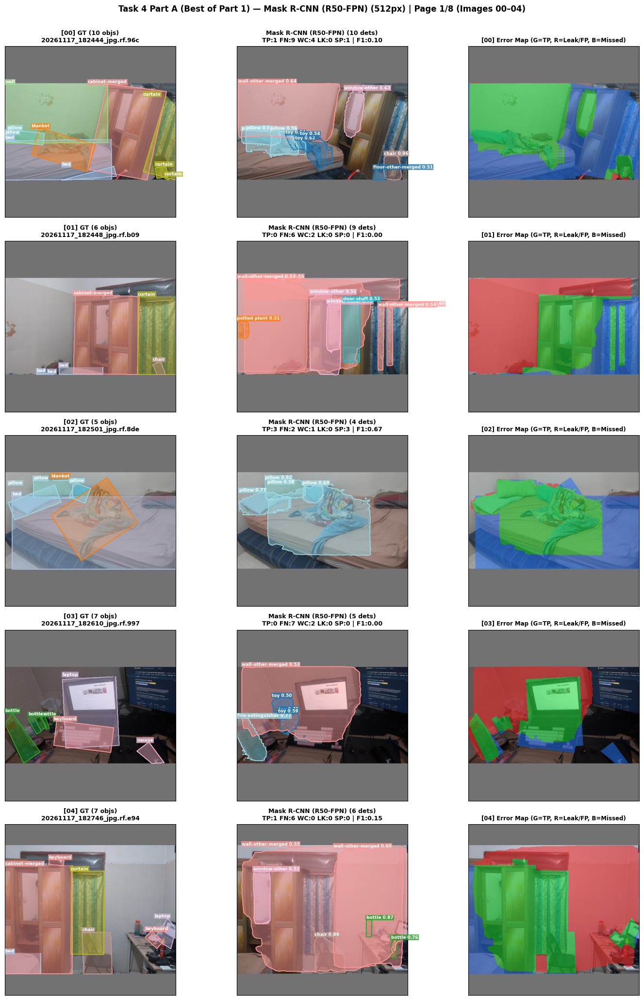

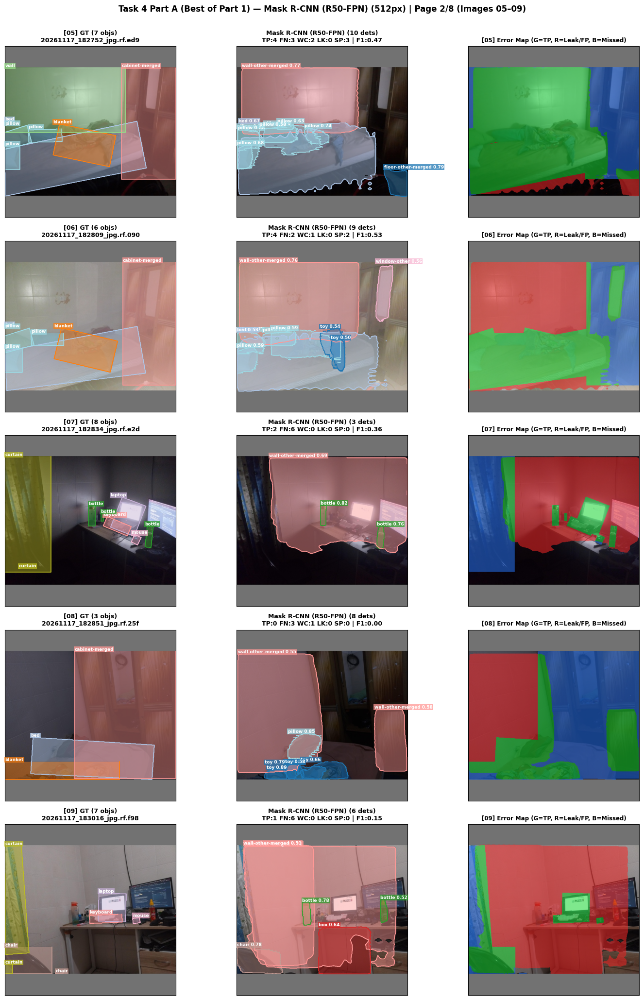

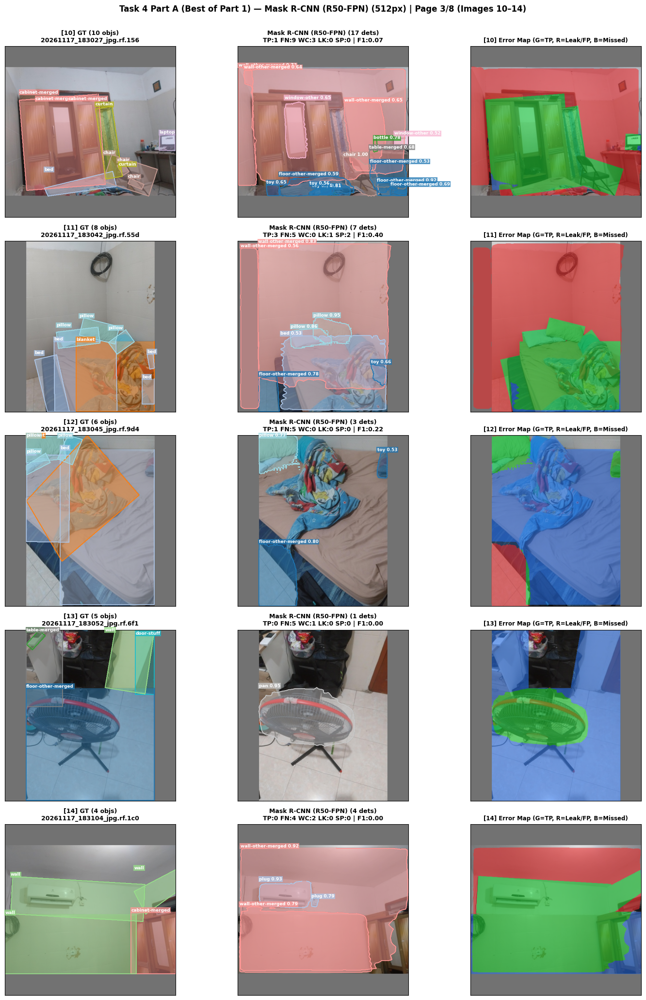

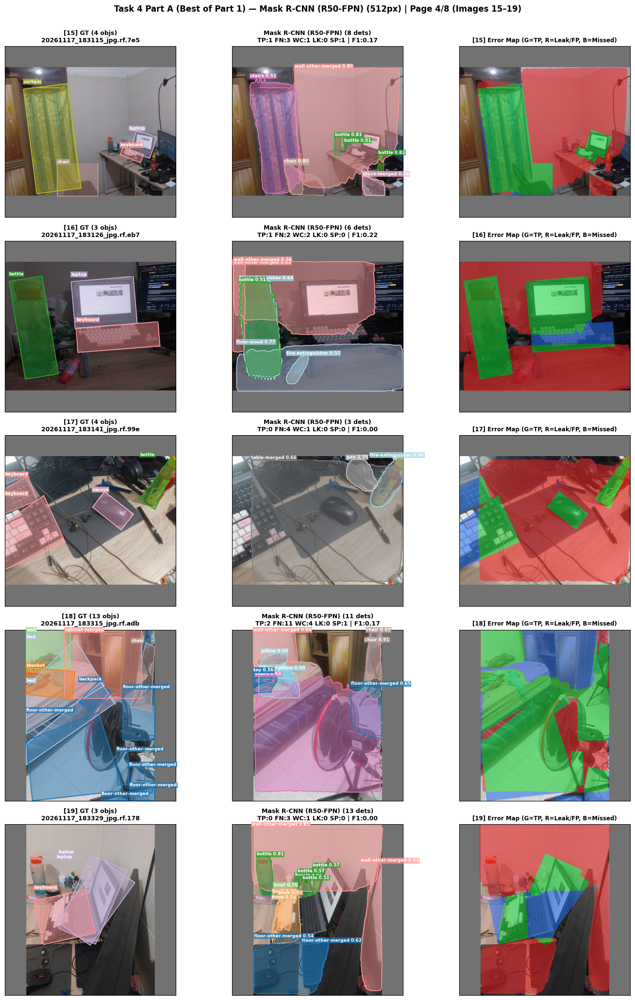

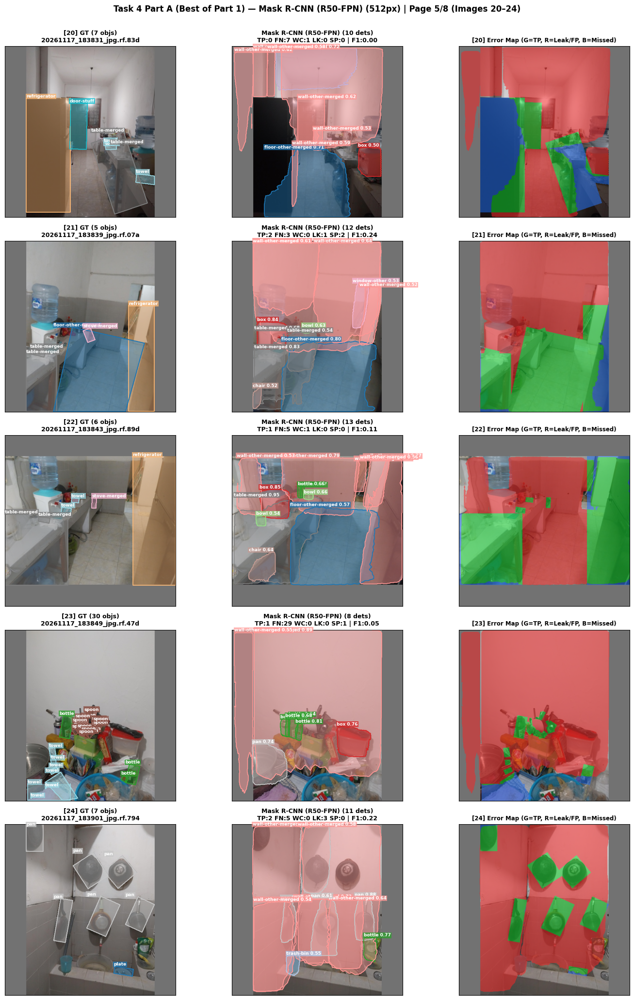

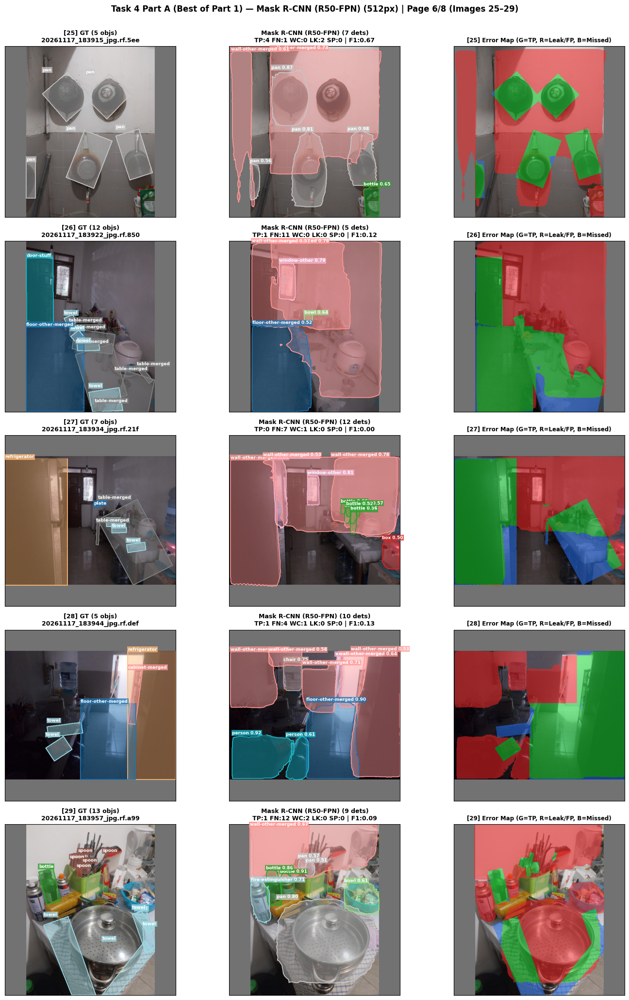

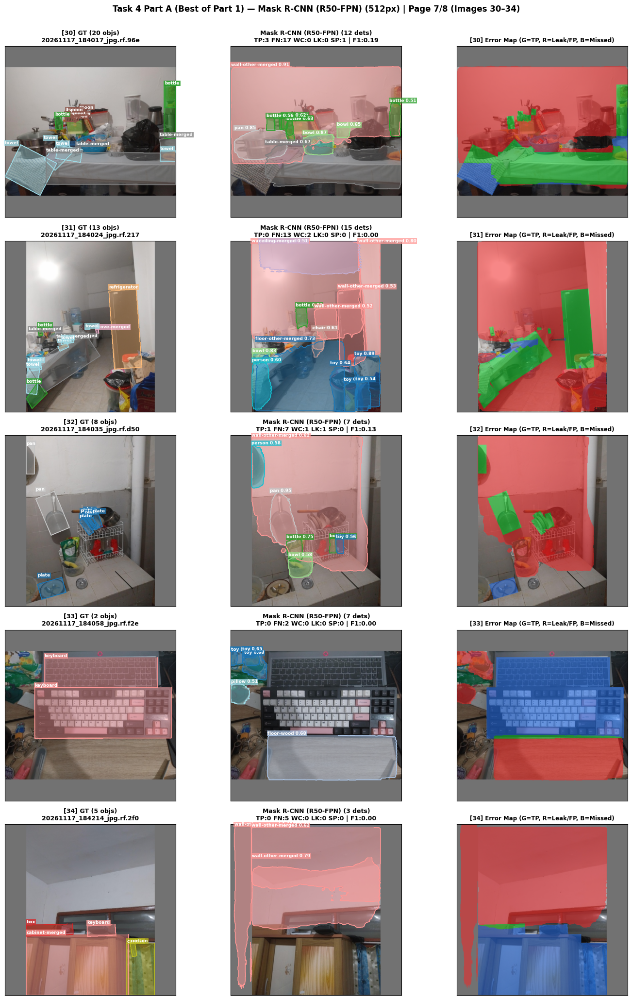

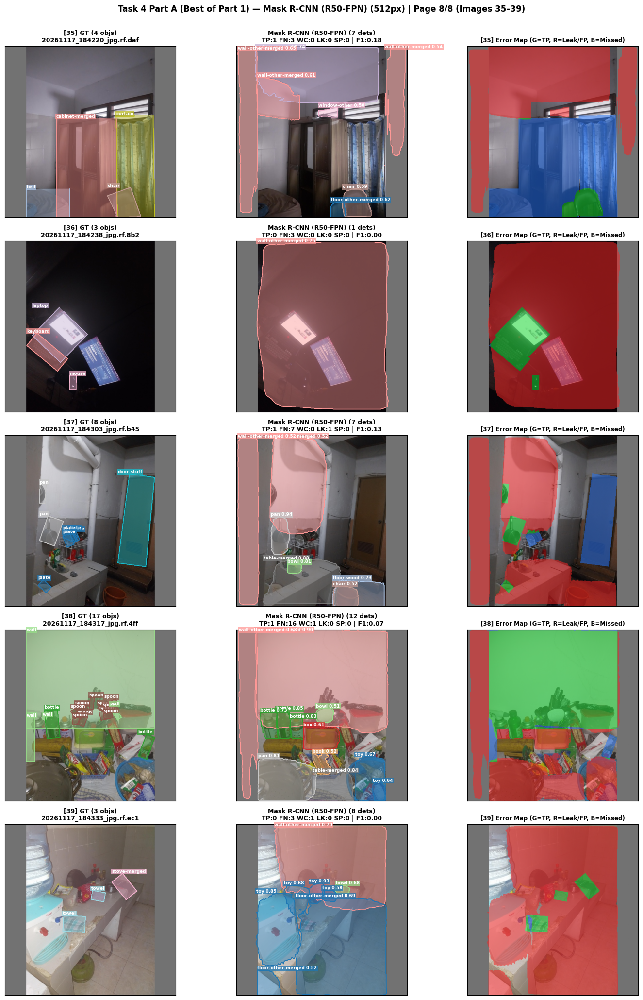

In [ ]:
# Task 4 — Part A: Full 40-image table & visual gallery for the Best Model from Part 1 (512px)
PART1_ALL40_CONF = None       # None -> use model default threshold, or set e.g. 0.35
PART1_IMAGES_PER_PAGE = 5     # 5 rows x 3 cols -> 8 pages for all 40 images
PART1_SHOW_ERROR_MAP = True   # True -> 3 cols (GT | Pred | Pixel Error Map); False -> 2 cols (GT | Pred)

print(f"=== Task 4 Part A: Per-Image Audit Table for {BEST_PART1_LABEL} (All 40 myroom/ Photos, sorted by TotalFail) ===")
display(BEST_P1_AUDIT_DF.sort_values(["TotalFail", "F1"], ascending=[False, True]).reset_index(drop=True))

display_all_40_results(
    PART1,
    BEST_PART1_KEY,
    BEST_P1_AUDIT_DF,
    save_subdir=FAIL_DIR / "part1_best_all40",
    part_title="Task 4 Part A (Best of Part 1)",
    conf_thr=PART1_ALL40_CONF,
    images_per_page=PART1_IMAGES_PER_PAGE,
    show_error_map=PART1_SHOW_ERROR_MAP,
)

### 6.3 Task 4 — Part B: All 40 `myroom/` Test Dataset Results (Best Model from Part 2)

Displays the full 40-image per-photo audit table and **all 40 test images** (`GT | Best Part 2 Prediction | Pixel Error Map`) in 8 clean pages (`5 images/page`) for the **Best Model from Part 2 (Augmentation Comparison, 640px)**.

=== Task 4 Part B: Per-Image Audit Table for Mask2Former (Aug 2) (All 40 myroom/ Photos, sorted by TotalFail) ===


,img_idx,file_name,n_gt,n_pred,TP,FP,Missed,WrongCls,MaskLeak,Split,TotalFail,Mean_TP_IoU,F1,missed_classes,wrong_class_pairs,leak_classes,split_classes
0,23,20261117_183849_jpg.rf.47ded812e5427a940ef4c32...,30,13,3,10,27,0,1,1,29,0.6645,0.1395,"spoon, spoon, spoon, spoon, spoon, spoon, spoo...",-,spoon(0.43),bottle(x3)
1,30,20261117_184017_jpg.rf.96e839931d3e4622a34df9e...,20,21,3,18,17,2,7,3,29,0.6583,0.1463,"spoon, spoon, spoon, spoon, spoon, spoon, spoo...","towel->paper, towel->paper","spoon(0.30), spoon(0.69), spoon(0.61), spoon(0...","spoon(x3), spoon(x2), bottle(x2)"
2,38,20261117_184317_jpg.rf.4ff7f7c1b56c38fda3b6012...,18,19,4,15,14,2,5,7,28,0.7082,0.2162,"wall, spoon, spoon, spoon, spoon, spoon, spoon...","wall->wall-other-merged, wall->wall-other-merged","spoon(0.31), spoon(0.58), spoon(0.69), spoon(0...","spoon(x2), spoon(x2), spoon(x2), spoon(x2), sp..."
3,18,20261117_183315_jpg.rf.adb2c6e771a773683a4d9f4...,13,17,4,13,9,2,6,3,20,0.6804,0.2667,"bed, bed, blanket, floor-other-merged, floor-o...","wall->wall-other-merged, cabinet-merged->wall-...","floor-other-merged(0.30), bed(0.47), floor-oth...","floor-other-merged(x2), floor-other-merged(x2)..."
4,10,20261117_183027_jpg.rf.156c8ba3e069d2a11ab4971...,10,23,0,23,10,5,2,0,17,0.0000,0.0000,"bed, cabinet-merged, cabinet-merged, cabinet-m...","cabinet-merged->wall-other-merged, curtain->wi...","chair(0.87), chair(0.91)",-
5,29,20261117_183957_jpg.rf.a99099e6b4c822d0d26e9d6...,13,16,3,13,10,2,2,1,15,0.6262,0.2069,"spoon, spoon, spoon, spoon, spoon, towel, towe...","spoon->food-other-merged, towel->counter","spoon(0.41), spoon(0.49)",bottle(x2)
6,31,20261117_184024_jpg.rf.217f1cfc35e165783d40c55...,13,14,0,14,13,1,0,0,14,0.0000,0.0000,"table-merged, towel, towel, towel, towel, refr...",table-merged->counter,-,-
7,26,20261117_183922_jpg.rf.85036621595f084294ee176...,12,11,1,10,11,1,0,1,13,0.9322,0.0870,"table-merged, table-merged, table-merged, tabl...",table-merged->wall-other-merged,-,floor-other-merged(x2)
8,0,20261117_182444_jpg.rf.96c8b5873d9807a8502837a...,10,14,3,11,7,4,0,1,12,0.8319,0.2500,"cabinet-merged, blanket, curtain, curtain, cur...","wall->wall-other-merged, curtain->chair, cabin...",-,pillow(x2)
9,32,20261117_184035_jpg.rf.d5018abafe59e384eed81f6...,8,17,5,12,3,0,3,5,11,0.6378,0.4000,"plate, plate, pan",-,"plate(0.39), plate(0.53), pan(0.52)","plate(x3), plate(x4), plate(x4), plate(x2), pl..."


Task 4 Part B (Best of Part 2): Mask2Former (Aug 2) (640px, conf>=0.5) — 40 images across 8 pages
Saving pages to: /content/inference_outputs/failure_analysis/part2_best_all40



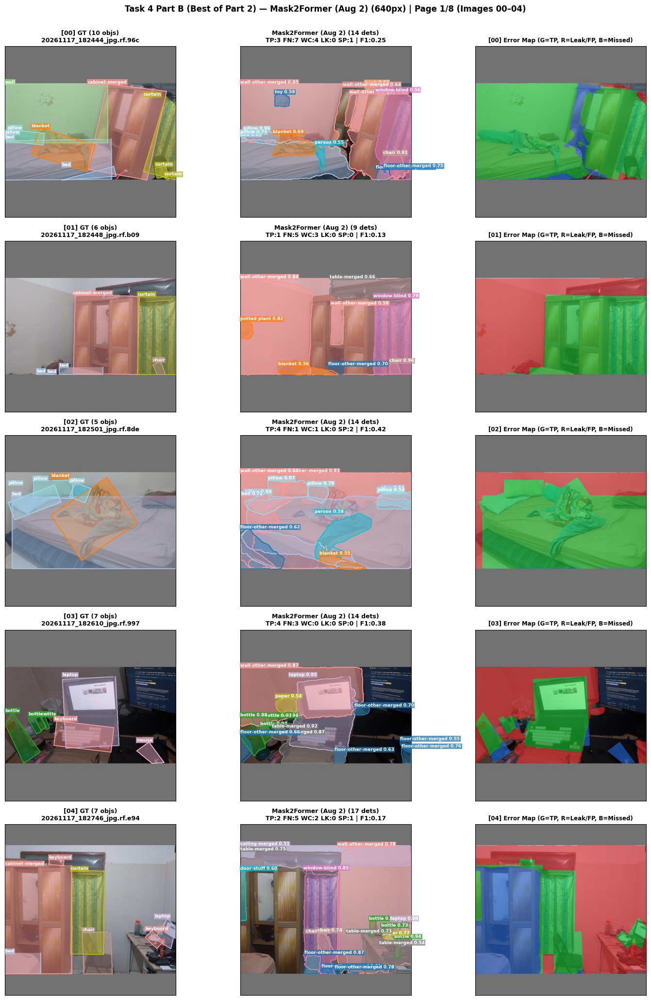

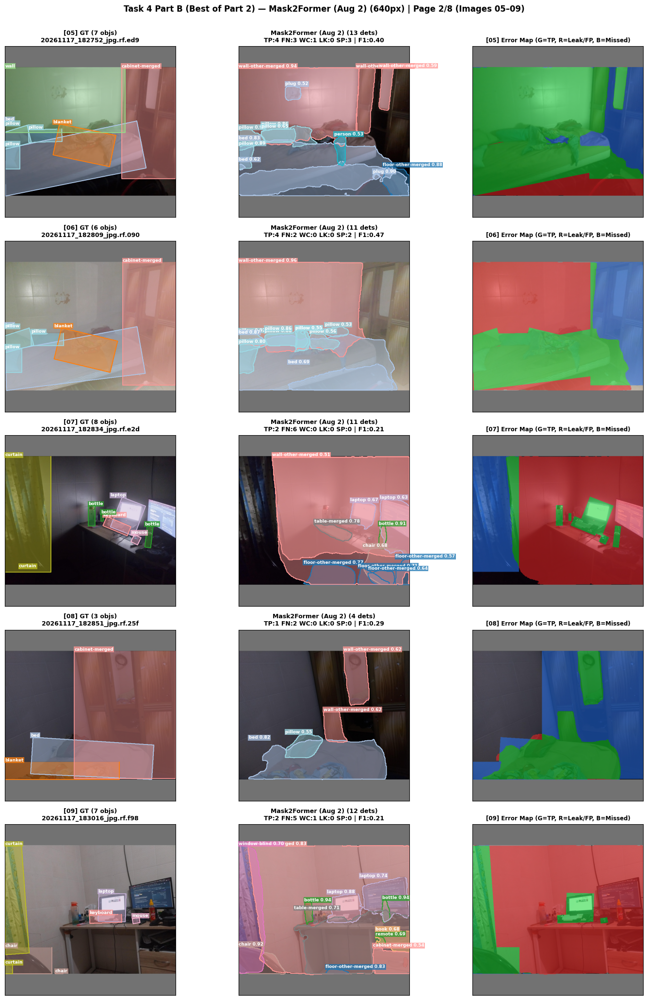

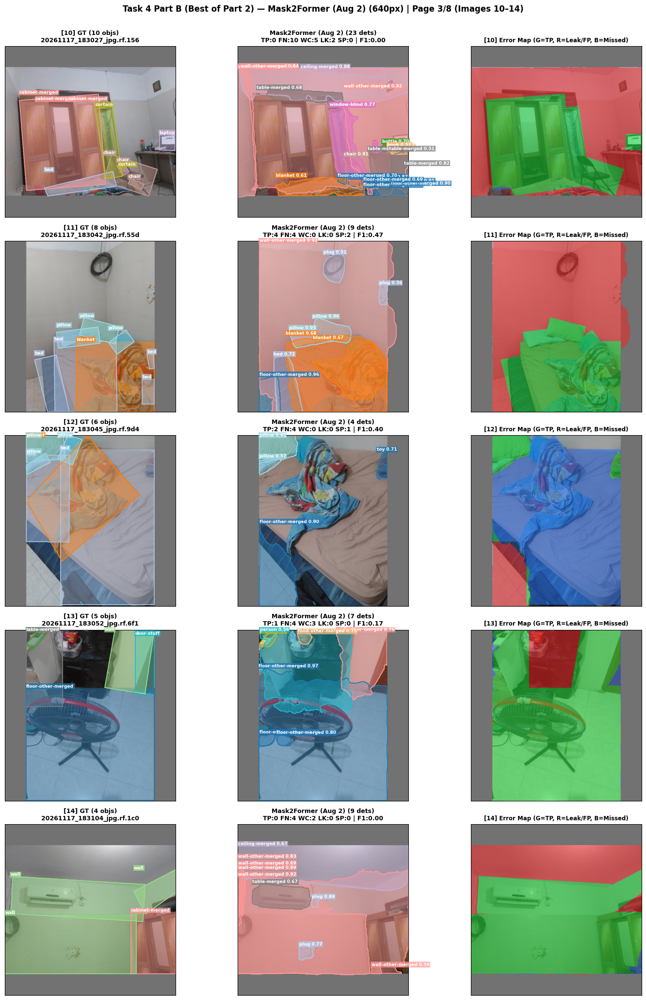

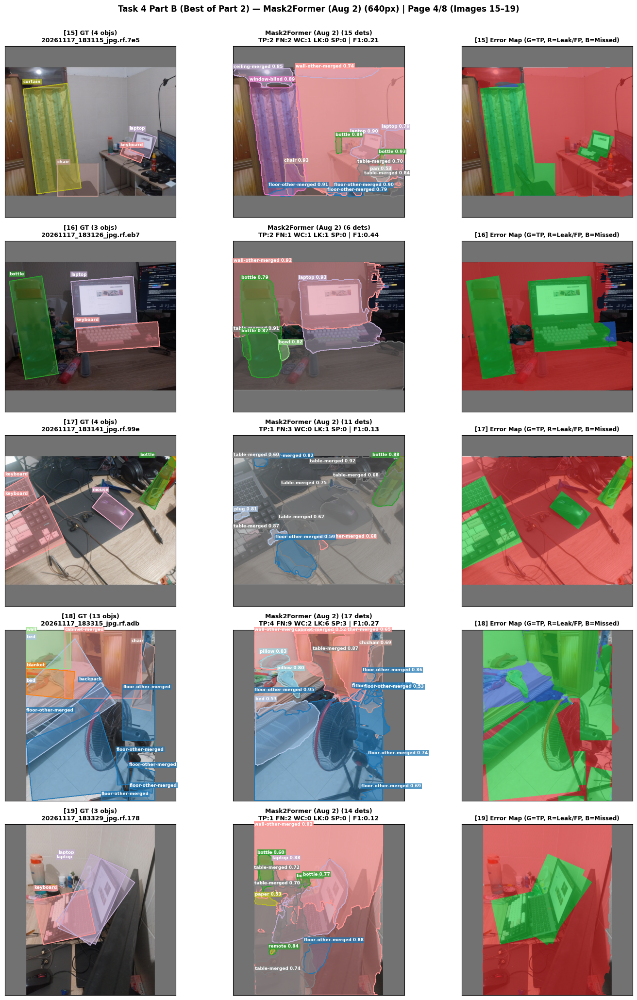

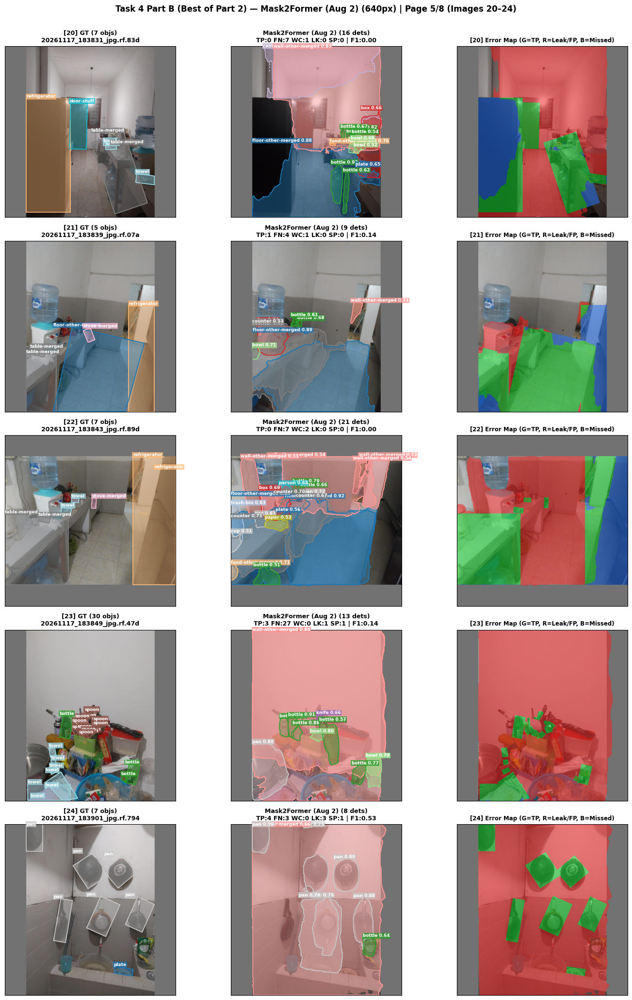

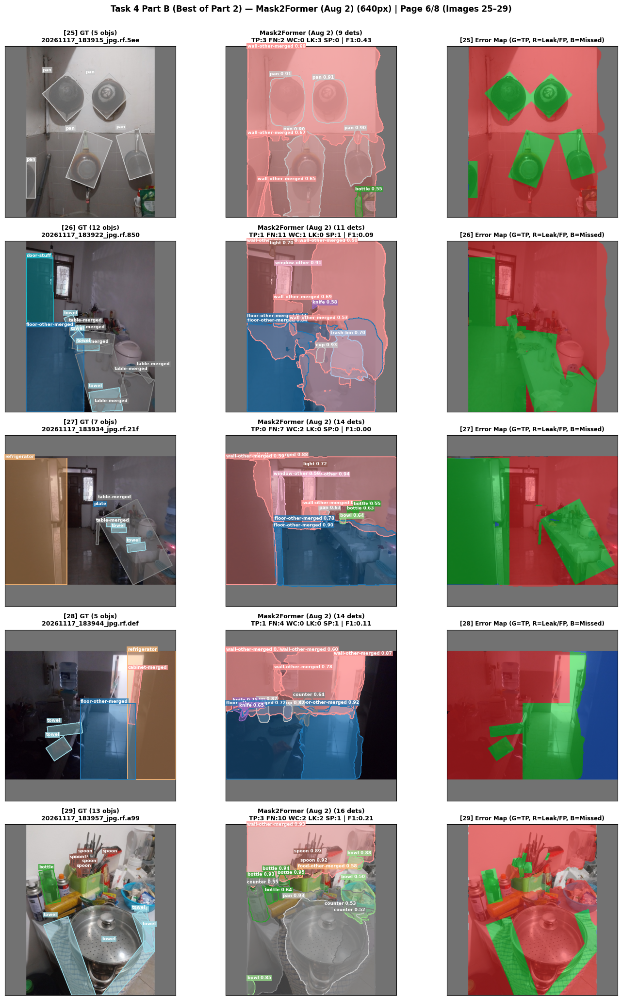

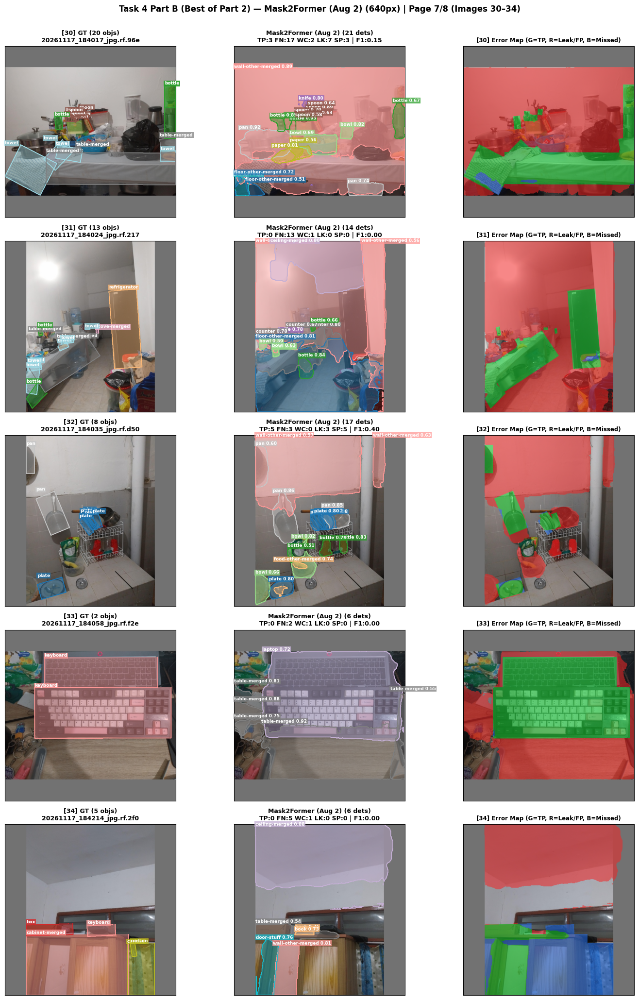

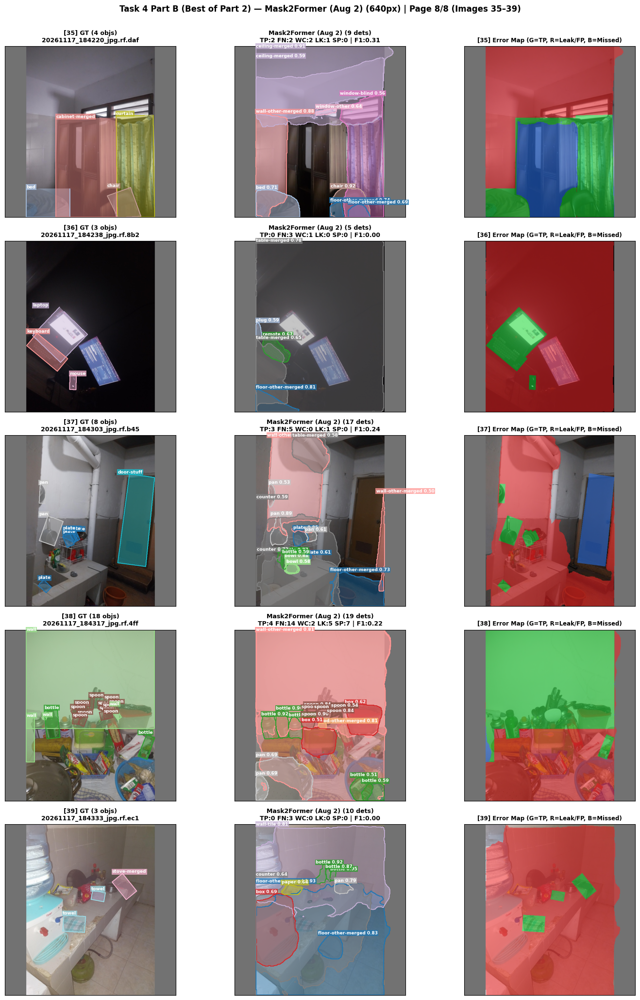

In [ ]:
# Task 4 — Part B: Full 40-image table & visual gallery for the Best Model from Part 2 (640px)
PART2_ALL40_CONF = None       # None -> use model default threshold, or set e.g. 0.50
PART2_IMAGES_PER_PAGE = 5     # 5 rows x 3 cols -> 8 pages for all 40 images
PART2_SHOW_ERROR_MAP = True   # True -> 3 cols (GT | Pred | Pixel Error Map); False -> 2 cols (GT | Pred)

print(f"=== Task 4 Part B: Per-Image Audit Table for {BEST_PART2_LABEL} (All 40 myroom/ Photos, sorted by TotalFail) ===")
display(BEST_P2_AUDIT_DF.sort_values(["TotalFail", "F1"], ascending=[False, True]).reset_index(drop=True))

display_all_40_results(
    PART2,
    BEST_PART2_KEY,
    BEST_P2_AUDIT_DF,
    save_subdir=FAIL_DIR / "part2_best_all40",
    part_title="Task 4 Part B (Best of Part 2)",
    conf_thr=PART2_ALL40_CONF,
    images_per_page=PART2_IMAGES_PER_PAGE,
    show_error_map=PART2_SHOW_ERROR_MAP,
)

### 6.4 Selected 5 Case Studies (`Best Part 1` vs `Best Part 2`) & Mini Proof Experiments

After reviewing the 40 images in **6.2 (Part A)** and **6.3 (Part B)**, plug your chosen 5 image indices into `CASE_STUDY_INDICES` below (or leave as `None` to auto-select 5 diverse failure cases) to generate a compact **5-photo side-by-side summary figure** comparing `GT | Best Part 1 | Best Part 2 | Error Map (Best P1) | Error Map (Best P2)`, followed by the **3 ready-to-run mini proof experiments** for Component 4.

Selected 5 case-study indices: [1, 12, 17, 19, 36]
  Case 1: [01] 20261117_182448_jpg.rf.b090d41bb665842d22c8f45375867c15.jpg
  Case 2: [12] 20261117_183045_jpg.rf.9d41180bfd434f55c3b18c5bd1270742.jpg
  Case 3: [17] 20261117_183141_jpg.rf.99e9f52a3f9f710f14a8f85ec819412b.jpg
  Case 4: [19] 20261117_183329_jpg.rf.17889127363ca1d2e111aca4b7b952f4.jpg
  Case 5: [36] 20261117_184238_jpg.rf.8b2eb40cde8a05f28bb50be6e7cba25b.jpg


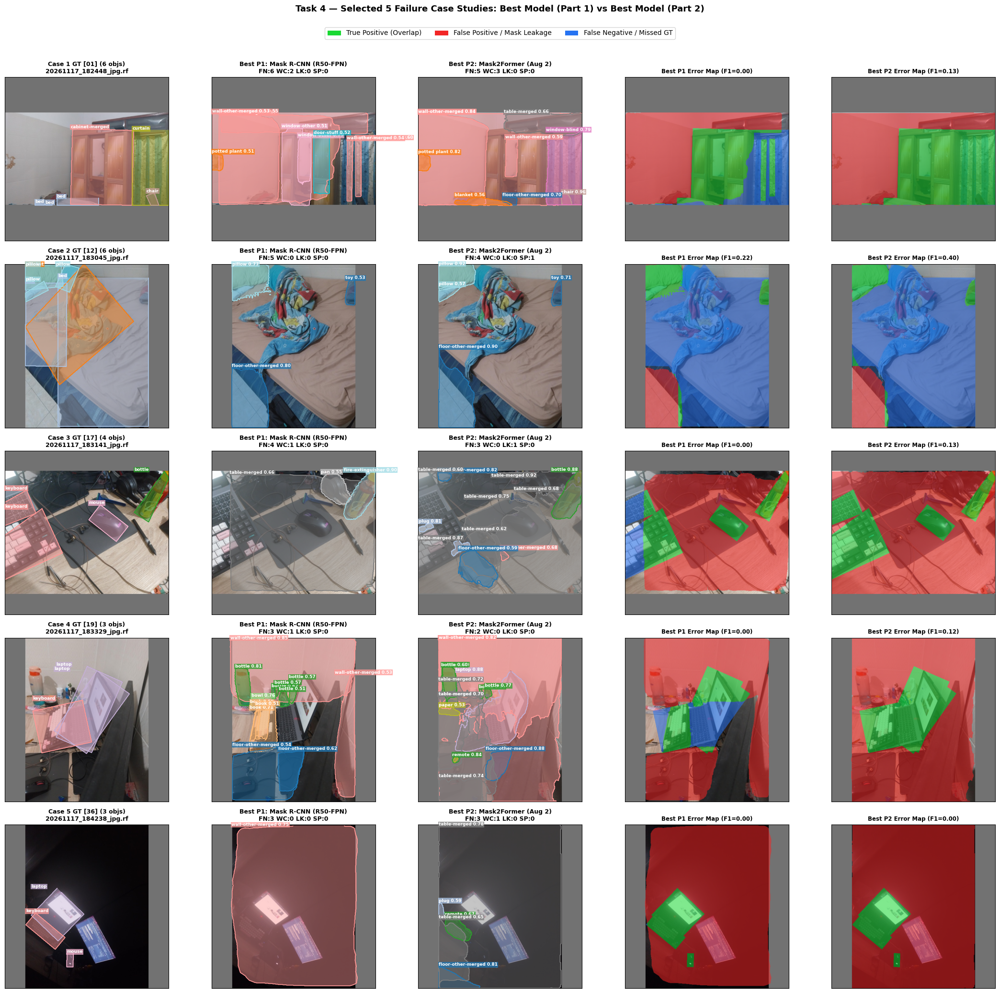


FAILURE LOG FOR SELECTED 5 CASE STUDIES (Best Part 1 vs Best Part 2)

--- Case 1 | Image [01] : 20261117_182448_jpg.rf.b090d41bb665842d22c8f45375867c15.jpg ---
  Best Part 1 (Mask R-CNN (R50-FPN))
    Missed   : bed(3036px), bed(180px), bed(88px), cabinet-merged(45451px), curtain(26790px), chair(986px)
    WrongCls : cabinet-merged->wall-other-merged(0.57), cabinet-merged->window-other(0.512) | Leak: none | Split: none
  Best Part 2 (Mask2Former (Aug 2))
    Missed   : bed(4592px), bed(259px), bed(108px), cabinet-merged(71010px), curtain(42042px)
    WrongCls : cabinet-merged->wall-other-merged(0.842), curtain->window-blind(0.79), bed->blanket(0.563) | Leak: none | Split: none

--- Case 2 | Image [12] : 20261117_183045_jpg.rf.9d41180bfd434f55c3b18c5bd1270742.jpg ---
  Best Part 1 (Mask R-CNN (R50-FPN))
    Missed   : bed(131595px), blanket(63462px), bed(33866px), pillow(2170px), pillow(3778px)
    WrongCls : none | Leak: none | Split: none
  Best Part 2 (Mask2Former (Aug 2))
    Misse

In [ ]:
# After inspecting all 40 images above, put YOUR 5 chosen image indices here (e.g. [3, 12, 18, 27, 34])
# Leave as None to auto-select 5 diverse failure photos.
CASE_STUDY_INDICES = [1, 12, 17, 19, 36]


def auto_pick_5_from_best(df_p1: pd.DataFrame, df_p2: pd.DataFrame) -> list[int]:
    comb = df_p1[["img_idx", "Missed", "WrongCls", "MaskLeak", "Split", "TotalFail"]].merge(
        df_p2[["img_idx", "Missed", "WrongCls", "MaskLeak", "Split", "TotalFail"]],
        on="img_idx", suffixes=("_p1", "_p2"),
    )
    for c in ("Missed", "WrongCls", "MaskLeak", "Split", "TotalFail"):
        comb[c] = comb[f"{c}_p1"] + comb[f"{c}_p2"]
    comb["n_types"] = (
        (comb["Missed"] > 0).astype(int) + (comb["WrongCls"] > 0).astype(int)
        + (comb["MaskLeak"] > 0).astype(int) + (comb["Split"] > 0).astype(int)
    )
    picked = []
    for col in ("Split", "MaskLeak", "WrongCls", "Missed"):
        sub = comb[(comb[col] > 0) & (~comb["img_idx"].isin(picked))].sort_values(
            [col, "n_types", "TotalFail"], ascending=False
        )
        if len(sub):
            picked.append(int(sub.iloc[0]["img_idx"]))
    for idx in comb.sort_values(["n_types", "TotalFail"], ascending=False)["img_idx"]:
        if len(picked) >= 5:
            break
        if int(idx) not in picked:
            picked.append(int(idx))
    return picked[:5]


SELECTED_5 = list(CASE_STUDY_INDICES) if CASE_STUDY_INDICES is not None else auto_pick_5_from_best(BEST_P1_AUDIT_DF, BEST_P2_AUDIT_DF)
print("Selected 5 case-study indices:", SELECTED_5)
for k, idx in enumerate(SELECTED_5, start=1):
    print(f"  Case {k}: [{idx:02d}] {EVAL_SET_512.images[idx].name}")

# Compact 5-case-study comparison figure: GT | Best Part 1 | Best Part 2 | ErrMap P1 | ErrMap P2
fig, axes = plt.subplots(len(SELECTED_5), 5, figsize=(21, 4.0 * len(SELECTED_5)))
if len(SELECTED_5) == 1:
    axes = axes[None, :]

for r, idx in enumerate(SELECTED_5):
    img512 = load_rgb(EVAL_SET_512.images[idx])
    gt512_m, gt512_l = load_gt_for_eval(EVAL_SET_512, idx)
    p1_pred = filter_pred(PART1["preds"][BEST_PART1_KEY][idx], score_thr=MODEL_REGISTRY[BEST_PART1_KEY]["default_conf"], max_det=30)
    r1 = BEST_P1_AUDIT_DF.loc[BEST_P1_AUDIT_DF["img_idx"] == idx].iloc[0]

    img640 = load_rgb(EVAL_SET_640.images[idx])
    gt640_m, gt640_l = load_gt_for_eval(EVAL_SET_640, idx)
    p2_pred = filter_pred(PART2["preds"][BEST_PART2_KEY][idx], score_thr=MODEL_REGISTRY[BEST_PART2_KEY]["default_conf"], max_det=30)
    r2 = BEST_P2_AUDIT_DF.loc[BEST_P2_AUDIT_DF["img_idx"] == idx].iloc[0]

    draw_instances(
        axes[r, 0], img512, gt512_m, gt512_l,
        title=f"Case {r+1} GT [{idx:02d}] ({len(gt512_m)} objs)\n{EVAL_SET_512.images[idx].stem[:22]}",
        legend=False, show_labels_on_mask=True, show_scores=False,
    )
    draw_instances(
        axes[r, 1], img512, p1_pred["masks"], p1_pred["labels"], p1_pred["scores"],
        title=f"Best P1: {BEST_PART1_LABEL}\nFN:{int(r1['Missed'])} WC:{int(r1['WrongCls'])} LK:{int(r1['MaskLeak'])} SP:{int(r1['Split'])}",
        legend=False, show_labels_on_mask=True, show_scores=True,
    )
    draw_instances(
        axes[r, 2], img640, p2_pred["masks"], p2_pred["labels"], p2_pred["scores"],
        title=f"Best P2: {BEST_PART2_LABEL}\nFN:{int(r2['Missed'])} WC:{int(r2['WrongCls'])} LK:{int(r2['MaskLeak'])} SP:{int(r2['Split'])}",
        legend=False, show_labels_on_mask=True, show_scores=True,
    )
    draw_pixel_error_map(axes[r, 3], img512, gt512_m, p1_pred["masks"], title=f"Best P1 Error Map (F1={r1['F1']:.2f})")
    draw_pixel_error_map(axes[r, 4], img640, gt640_m, p2_pred["masks"], title=f"Best P2 Error Map (F1={r2['F1']:.2f})")

legend_handles = [
    Patch(facecolor=(0.1, 0.85, 0.2), label="True Positive (Overlap)"),
    Patch(facecolor=(0.95, 0.15, 0.15), label="False Positive / Mask Leakage"),
    Patch(facecolor=(0.15, 0.45, 0.95), label="False Negative / Missed GT"),
]
fig.legend(handles=legend_handles, loc="upper center", ncol=3, fontsize=10, bbox_to_anchor=(0.5, 1.015))
plt.suptitle("Task 4 — Selected 5 Failure Case Studies: Best Model (Part 1) vs Best Model (Part 2)", fontsize=13, fontweight="bold", y=1.035)
plt.tight_layout()
plt.savefig(FAIL_DIR / "case_studies_5_best_p1_vs_p2.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

# Structured failure log for the 5 chosen photos (both Best Part 1 & Best Part 2)
print("\n" + "=" * 92)
print("FAILURE LOG FOR SELECTED 5 CASE STUDIES (Best Part 1 vs Best Part 2)")
print("=" * 92)
for rank_pos, idx in enumerate(SELECTED_5, start=1):
    print(f"\n--- Case {rank_pos} | Image [{idx:02d}] : {EVAL_SET_512.images[idx].name} ---")
    for tag_lbl, d in ((f"Best Part 1 ({BEST_PART1_LABEL})", BEST_P1_DETAILS[idx]),
                       (f"Best Part 2 ({BEST_PART2_LABEL})", BEST_P2_DETAILS[idx])):
        missed_str = ", ".join(f"{x['class']}({x['gt_area_px']}px)" for x in d["missed"]) or "none"
        wc_str = ", ".join(f"{x['gt_class']}->{x['pred_class']}({x['score']})" for x in d["wrong_class"]) or "none"
        lk_str = ", ".join(f"{x['class']}(out={x['outside_ratio']},iou={x['iou']})" for x in d["mask_leak"]) or "none"
        sp_str = ", ".join(f"{x['class']}(x{x['n_fragments']})" for x in d["split_obj"]) or "none"
        print(f"  {tag_lbl}")
        print(f"    Missed   : {missed_str}")
        print(f"    WrongCls : {wc_str} | Leak: {lk_str} | Split: {sp_str}")

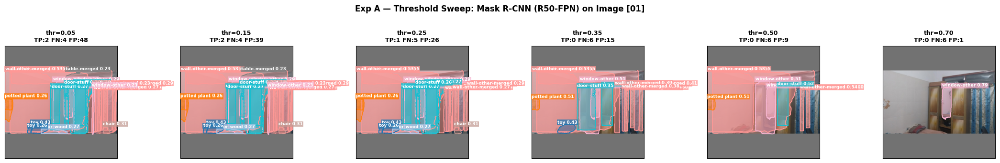

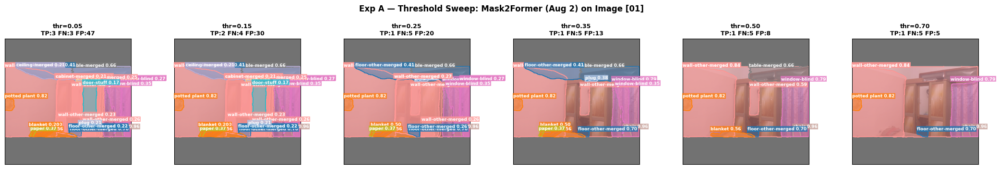

,model,threshold,n_pred,TP,FP,Missed,WrongCls,Leak,Split,F1
0,Mask R-CNN (R50-FPN),0.0500,50,2,48,4,13,0,0,0.0714
1,Mask R-CNN (R50-FPN),0.1500,41,2,39,4,9,0,0,0.0851
2,Mask R-CNN (R50-FPN),0.2500,27,1,26,5,6,0,0,0.0606
3,Mask R-CNN (R50-FPN),0.3500,15,0,15,6,3,0,0,0.0000
4,Mask R-CNN (R50-FPN),0.5000,9,0,9,6,2,0,0,0.0000
5,Mask R-CNN (R50-FPN),0.7000,1,0,1,6,0,0,0,0.0000
6,Mask2Former (Aug 2),0.0500,50,3,47,3,15,0,1,0.1071
7,Mask2Former (Aug 2),0.1500,32,2,30,4,9,0,0,0.1053
8,Mask2Former (Aug 2),0.2500,21,1,20,5,6,0,0,0.0741
9,Mask2Former (Aug 2),0.3500,14,1,13,5,3,0,0,0.1000


In [ ]:
# ==============================================================================
# Mini Proof Experiment A: Confidence Threshold Sweep (Best Part 1 & Best Part 2)
# ==============================================================================
EXP_A_IMG_IDX = SELECTED_5[0]                    # change to any image index 0..39
EXP_A_MODEL_KEYS = [BEST_PART1_KEY, BEST_PART2_KEY]
EXP_A_THRESHOLDS = [0.05, 0.15, 0.25, 0.35, 0.50, 0.70]

sweep_rows = []
for mkey in EXP_A_MODEL_KEYS:
    cfg = MODEL_REGISTRY[mkey]
    suite = PART1 if cfg["part"] == "part1" else PART2
    ev = suite["eval_set"]
    img = load_rgb(ev.images[EXP_A_IMG_IDX])
    gt_m, gt_l = load_gt_for_eval(ev, EXP_A_IMG_IDX)
    raw_pred = suite["preds"][mkey][EXP_A_IMG_IDX]

    fig, axes = plt.subplots(1, len(EXP_A_THRESHOLDS), figsize=(3.5 * len(EXP_A_THRESHOLDS), 3.9))
    for ax, thr in zip(axes, EXP_A_THRESHOLDS):
        res = audit_single_image(gt_m, gt_l, raw_pred, score_thr=thr)
        pf = filter_pred(raw_pred, score_thr=thr, max_det=30)
        sweep_rows.append({
            "model": cfg["label"], "threshold": thr, "n_pred": res["n_pred"],
            "TP": res["tp"], "FP": res["fp"], "Missed": res["missed"],
            "WrongCls": res["wrong_class"], "Leak": res["mask_leak"],
            "Split": res["split_obj"], "F1": res["f1"],
        })
        draw_instances(
            ax, img, pf["masks"], pf["labels"], pf["scores"],
            title=f"thr={thr:.2f}\nTP:{res['tp']} FN:{res['missed']} FP:{res['fp']}",
            legend=False, show_labels_on_mask=True, show_scores=True,
        )
    plt.suptitle(f"Exp A — Threshold Sweep: {cfg['label']} on Image [{EXP_A_IMG_IDX:02d}]", fontweight="bold")
    plt.tight_layout()
    plt.savefig(FAIL_DIR / f"expA_thr_sweep_{mkey}_img{EXP_A_IMG_IDX}.png", dpi=150)
    plt.show()
    plt.close(fig)

display(pd.DataFrame(sweep_rows))

Exp B target: Image [01] (auto-crop around 'bed'), raw crop box=(948, 2143, 1228, 2296)


Loading weights:   0%|          | 0/556 [00:00<?, ?it/s]

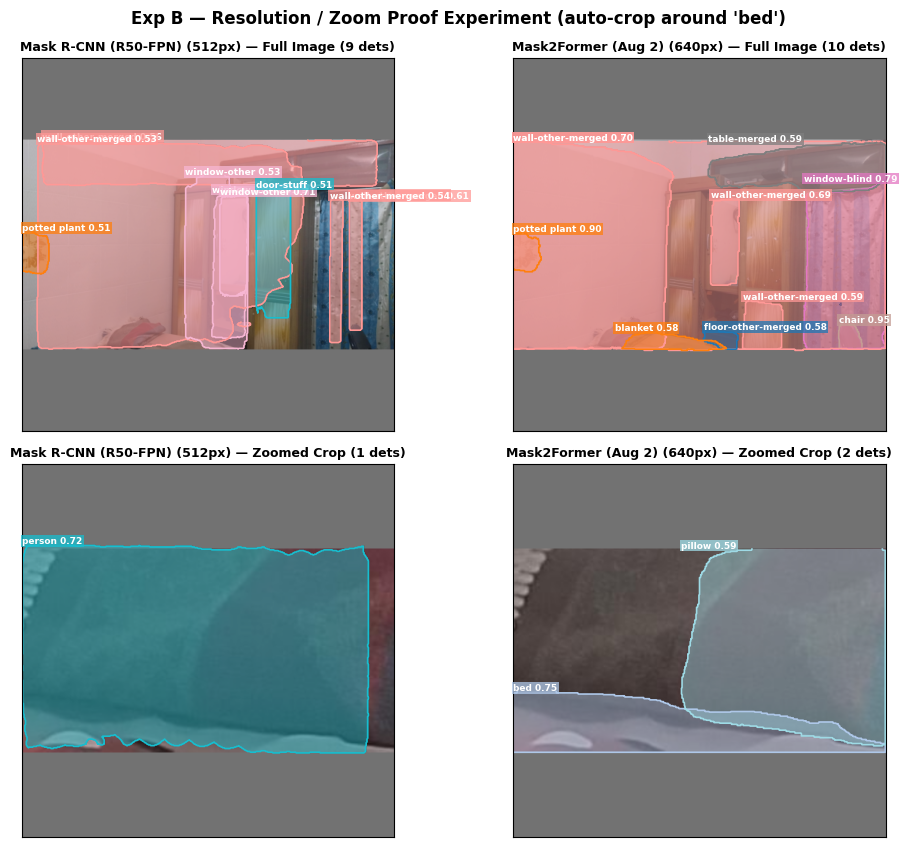

In [ ]:
# ==============================================================================
# Mini Proof Experiment B: Zoom / Crop Resolution Test (Full Image vs Cropped Region)
# ==============================================================================
EXP_B_IMG_IDX = SELECTED_5[0]                    # change to any image index 0..39
EXP_B_MODEL_KEYS = [BEST_PART1_KEY, BEST_PART2_KEY]
# Optional manual normalized crop [x1, y1, x2, y2] in 0..1; None -> auto-crop around smallest GT object
EXP_B_CROP_NORM = None
EXP_B_PAD_FRAC = 0.35

raw_img_b_path = MYROOM_RAW_IMAGES[EXP_B_IMG_IDX]
raw_img_b = open_oriented_rgb(raw_img_b_path)
W_raw, H_raw = raw_img_b.size
raw_insts_b = read_labels(label_for_raw(raw_img_b_path), W_raw, H_raw, class_map=MYROOM_TO_TRAIN_ID)

if EXP_B_CROP_NORM is not None:
    cx1, cy1, cx2, cy2 = [int(v * d) for v, d in zip(EXP_B_CROP_NORM, (W_raw, H_raw, W_raw, H_raw))]
    crop_label = "custom crop"
else:
    if not raw_insts_b:
        raise ValueError("No GT instances in selected image; set EXP_B_CROP_NORM manually.")
    areas = [abs(cv2.contourArea(inst["poly"].astype(np.float32))) for inst in raw_insts_b]
    target_inst = raw_insts_b[int(np.argmin(areas))]
    px1, py1 = target_inst["poly"].min(0)
    px2, py2 = target_inst["poly"].max(0)
    bw, bh = max(px2 - px1, 64), max(py2 - py1, 64)
    side = max(bw, bh) * (1.0 + 2 * EXP_B_PAD_FRAC)
    mx, my = (px1 + px2) / 2, (py1 + py2) / 2
    cx1 = max(0, int(mx - side / 2))
    cy1 = max(0, int(my - side / 2))
    cx2 = min(W_raw, int(mx + side / 2))
    cy2 = min(H_raw, int(my + side / 2))
    crop_label = f"auto-crop around '{CLASS_NAMES[target_inst['cls']]}'"

cropped_pil = raw_img_b.crop((cx1, cy1, cx2, cy2))
print(f"Exp B target: Image [{EXP_B_IMG_IDX:02d}] ({crop_label}), raw crop box=({cx1}, {cy1}, {cx2}, {cy2})")

fig, axes = plt.subplots(2, len(EXP_B_MODEL_KEYS), figsize=(4.8 * len(EXP_B_MODEL_KEYS), 8.6))
if len(EXP_B_MODEL_KEYS) == 1:
    axes = axes[:, None]

for col, key in enumerate(EXP_B_MODEL_KEYS):
    cfg = MODEL_REGISTRY[key]
    S = cfg["img_size"]
    full_im, _ = letterbox_image(raw_img_b, S, mode=RESIZE_MODE, pad_value=PAD_VALUE)
    crop_im, _ = letterbox_image(cropped_pil, S, mode=RESIZE_MODE, pad_value=PAD_VALUE)
    bundle = load_model_bundle(key)
    preds_b = predict_with_bundle(bundle, [np.asarray(full_im), np.asarray(crop_im)], conf=cfg["default_conf"], max_det=25)
    unload_model_bundle(bundle)

    draw_instances(
        axes[0, col], np.asarray(full_im), preds_b[0]["masks"], preds_b[0]["labels"], preds_b[0]["scores"],
        title=f"{cfg['label']} ({S}px) — Full Image ({len(preds_b[0]['masks'])} dets)",
        legend=False, show_labels_on_mask=True, show_scores=True,
    )
    draw_instances(
        axes[1, col], np.asarray(crop_im), preds_b[1]["masks"], preds_b[1]["labels"], preds_b[1]["scores"],
        title=f"{cfg['label']} ({S}px) — Zoomed Crop ({len(preds_b[1]['masks'])} dets)",
        legend=False, show_labels_on_mask=True, show_scores=True,
    )

plt.suptitle(f"Exp B — Resolution / Zoom Proof Experiment ({crop_label})", fontweight="bold")
plt.tight_layout()
plt.savefig(FAIL_DIR / f"expB_zoom_img{EXP_B_IMG_IDX}.png", dpi=150)
plt.show()
plt.close(fig)

Loading weights:   0%|          | 0/556 [00:00<?, ?it/s]

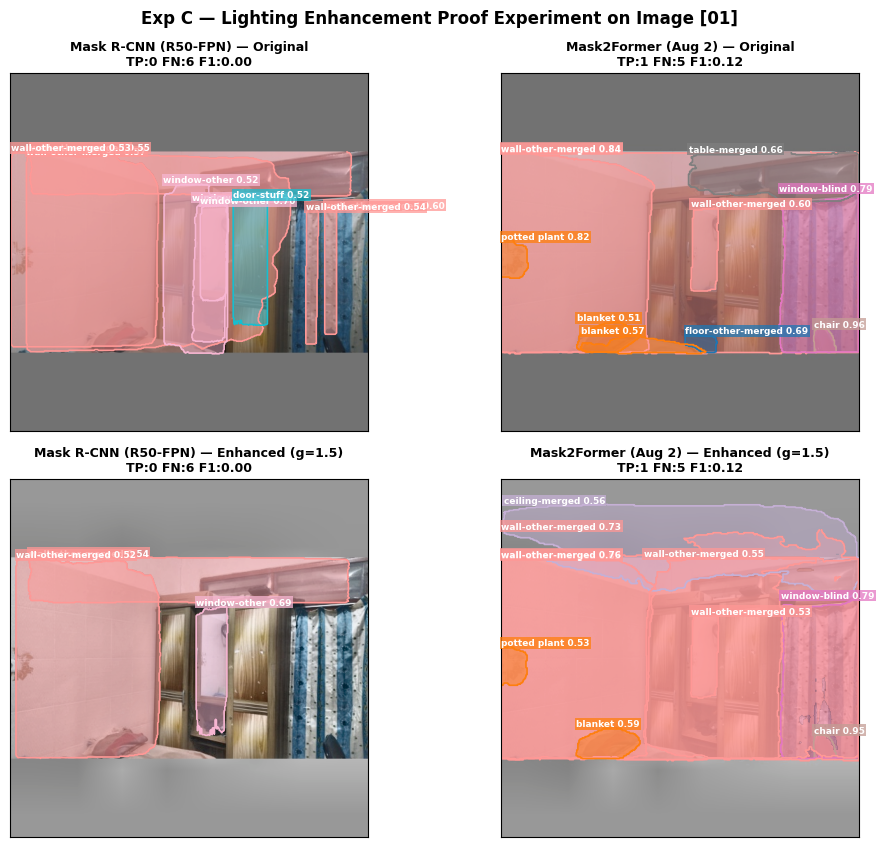

,model,condition,TP,Missed,WrongCls,F1
0,Mask R-CNN (R50-FPN),Original,0,6,2,0.0000
1,Mask R-CNN (R50-FPN),CLAHE+Gamma(1.5),0,6,0,0.0000
2,Mask2Former (Aug 2),Original,1,5,3,0.1250
3,Mask2Former (Aug 2),CLAHE+Gamma(1.5),1,5,3,0.1250


In [ ]:
# ==============================================================================
# Mini Proof Experiment C: Lighting / Exposure Enhancement (Original vs CLAHE + Gamma)
# ==============================================================================
EXP_C_IMG_IDX = SELECTED_5[0]                    # pick a dark or backlit myroom photo (0..39)
EXP_C_MODEL_KEYS = [BEST_PART1_KEY, BEST_PART2_KEY]
EXP_C_GAMMA = 1.5                                # >1.0 brightens dark areas; <1.0 darkens overexposed areas
EXP_C_CLAHE_CLIP = 2.5


def enhance_lighting(rgb: np.ndarray, gamma: float = 1.5, clahe_clip: float = 2.5) -> np.ndarray:
    inv_g = 1.0 / max(gamma, 1e-3)
    lut = np.array([((i / 255.0) ** inv_g) * 255 for i in range(256)], dtype=np.uint8)
    g_img = cv2.LUT(rgb, lut)
    lab = cv2.cvtColor(g_img, cv2.COLOR_RGB2LAB)
    l_ch, a_ch, b_ch = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=clahe_clip, tileGridSize=(8, 8))
    l_eq = clahe.apply(l_ch)
    return cv2.cvtColor(cv2.merge([l_eq, a_ch, b_ch]), cv2.COLOR_LAB2RGB)


fig, axes = plt.subplots(2, len(EXP_C_MODEL_KEYS), figsize=(4.8 * len(EXP_C_MODEL_KEYS), 8.6))
if len(EXP_C_MODEL_KEYS) == 1:
    axes = axes[:, None]

exp_c_rows = []
for col, key in enumerate(EXP_C_MODEL_KEYS):
    cfg = MODEL_REGISTRY[key]
    ev_set = EVAL_SETS[cfg["img_size"]]
    orig_rgb = load_rgb(ev_set.images[EXP_C_IMG_IDX])
    enh_rgb = enhance_lighting(orig_rgb, gamma=EXP_C_GAMMA, clahe_clip=EXP_C_CLAHE_CLIP)
    gt_m_c, gt_l_c = load_gt_for_eval(ev_set, EXP_C_IMG_IDX)

    bundle = load_model_bundle(key)
    preds_c = predict_with_bundle(bundle, [orig_rgb, enh_rgb], conf=cfg["default_conf"], max_det=30)
    unload_model_bundle(bundle)

    a_orig = audit_single_image(gt_m_c, gt_l_c, preds_c[0], score_thr=cfg["default_conf"])
    a_enh = audit_single_image(gt_m_c, gt_l_c, preds_c[1], score_thr=cfg["default_conf"])
    exp_c_rows.append({"model": cfg["label"], "condition": "Original", "TP": a_orig["tp"], "Missed": a_orig["missed"], "WrongCls": a_orig["wrong_class"], "F1": a_orig["f1"]})
    exp_c_rows.append({"model": cfg["label"], "condition": f"CLAHE+Gamma({EXP_C_GAMMA})", "TP": a_enh["tp"], "Missed": a_enh["missed"], "WrongCls": a_enh["wrong_class"], "F1": a_enh["f1"]})

    draw_instances(
        axes[0, col], orig_rgb, preds_c[0]["masks"], preds_c[0]["labels"], preds_c[0]["scores"],
        title=f"{cfg['label']} — Original\nTP:{a_orig['tp']} FN:{a_orig['missed']} F1:{a_orig['f1']:.2f}",
        legend=False, show_labels_on_mask=True, show_scores=True,
    )
    draw_instances(
        axes[1, col], enh_rgb, preds_c[1]["masks"], preds_c[1]["labels"], preds_c[1]["scores"],
        title=f"{cfg['label']} — Enhanced (g={EXP_C_GAMMA})\nTP:{a_enh['tp']} FN:{a_enh['missed']} F1:{a_enh['f1']:.2f}",
        legend=False, show_labels_on_mask=True, show_scores=True,
    )

plt.suptitle(f"Exp C — Lighting Enhancement Proof Experiment on Image [{EXP_C_IMG_IDX:02d}]", fontweight="bold")
plt.tight_layout()
plt.savefig(FAIL_DIR / f"expC_lighting_img{EXP_C_IMG_IDX}.png", dpi=150)
plt.show()
plt.close(fig)
display(pd.DataFrame(exp_c_rows))

## 7. Interactive Inference Playground (Normal Image Inference — No Ground Truth)

Run standard instance-segmentation inference on **any image** (no ground-truth labels required). Modify **only the parameters at the top of the cell below** and re-run it anytime:
- **Change Model (`MODEL_CHOICE`)**: `"yolo"`, `"maskrcnn"`, `"mask2former"`, `"m2f_no_aug"`, `"m2f_aug_1"`, `"m2f_aug_2"`, `"all_part1"`, `"all_part2"`, `"all"`, or a list like `["maskrcnn", "m2f_aug_2"]`.
- **Change Picture (`IMAGE_SOURCE`)**:
  - **any image path** (e.g. `"/content/new_photo.jpg"` or `r"C:/path/to/photo.jpg"`), OR
  - a filename inside `myroom/test/images/`, OR
  - an integer index `0..39` from `myroom/`.
- **Change Thresholds & Filters**: `CONF_THRESHOLD`, `MASK_THRESHOLD`, `IOU_THRESHOLD` (YOLO NMS), `MAX_DET`, and `CLASS_FILTER` (e.g. `["chair", "pillow"]`).
- **Visual Options**: `SHOW_ORIGINAL`, `SHOW_BOXES`, `SHOW_LABELS`, `SHOW_SCORES`, `SHOW_LEGEND`, `MASK_ALPHA`, `RESIZE_MODE_PG`, `SAVE_OUTPUT_NAME`.

The cell automatically respects EXIF orientation and keeps at most 1 model resident on GPU (`_PLAYGROUND_CACHE`) so tweaking thresholds or images on the same model runs quickly within 6 GB VRAM.

Image : WhatsApp Image 2026-11-25 at 13.05.34.jpeg  (raw size: 1600x900)
Models: ['Mask2Former (No Aug)', 'Mask2Former (Aug 1)', 'Mask2Former (Aug 2)']
Params: conf=0.35, mask_thr=0.5, iou=0.6, max_det=25, filter=None


Loading weights:   0%|          | 0/556 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/556 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/556 [00:00<?, ?it/s]

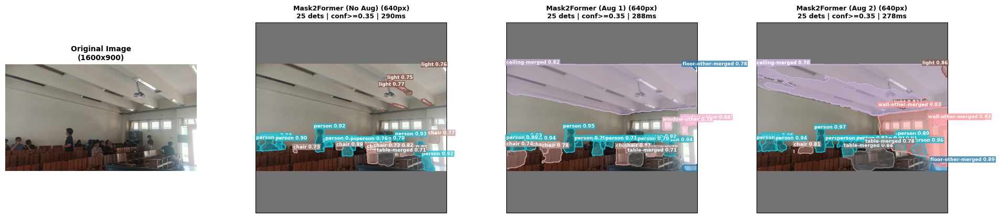

,model,det_#,class,score,area_px,bbox_xyxy
0,Mask2Former (No Aug),1,person,0.9418,1721,"(225, 400, 568, 453)"
1,Mask2Former (No Aug),2,person,0.9408,1506,"(289, 397, 326, 449)"
2,Mask2Former (No Aug),3,person,0.9315,1201,"(467, 380, 496, 433)"
3,Mask2Former (No Aug),4,person,0.9211,2338,"(14, 385, 91, 433)"
4,Mask2Former (No Aug),5,person,0.9170,2738,"(195, 355, 259, 436)"
...,...,...,...,...,...,...
70,Mask2Former (Aug 2),21,wall-other-merged,0.8258,33433,"(407, 282, 639, 478)"
71,Mask2Former (Aug 2),22,person,0.8199,483,"(334, 395, 358, 419)"
72,Mask2Former (Aug 2),23,chair,0.8052,1134,"(124, 415, 189, 441)"
73,Mask2Former (Aug 2),24,table-merged,0.7808,928,"(364, 405, 421, 439)"


In [17]:
MODEL_CHOICE = "all_part2"     # "yolo" | "maskrcnn" | "mask2former" | "m2f_no_aug" | "m2f_aug_1" | "m2f_aug_2" | "all_part1" | "all_part2" | "all" | list of keys
IMAGE_SOURCE = "/content/drive/MyDrive/comvis/WhatsApp Image 2026-11-25 at 13.05.34.jpeg"              # full path to ANY image (e.g. "/content/photo.jpg") | filename in myroom/test/images | int (0..39 in myroom)
CONF_THRESHOLD = 0.35          # confidence score threshold (0.0 .. 1.0)
MASK_THRESHOLD = 0.50          # pixel mask binarization threshold (0.0 .. 1.0)
IOU_THRESHOLD = 0.60           # NMS IoU threshold (used by YOLO11n-seg)
MAX_DET = 25                   # maximum number of detections to display
CLASS_FILTER = None            # None = all classes | or list of names, e.g. ["bed", "pillow", "chair"]

SHOW_ORIGINAL = True           # show the clean input image alongside model predictions
SHOW_BOXES = False             # draw dashed bounding boxes around masks
SHOW_LABELS = True             # draw class name labels on maskss
SHOW_SCORES = True             # include confidence scores next to labels
SHOW_LEGEND = False            # show corner legend box
MASK_ALPHA = 0.45              # mask overlay opacity (0.0 .. 1.0)
RESIZE_MODE_PG = "pad"         # "pad" (letterbox, recommended) | "stretch"

SAVE_OUTPUT_NAME = None        # Optional: e.g. "demo_result.png" -> saves inside inference_outputs/playground/
# ==============================================================================

if "_PLAYGROUND_CACHE" not in globals():
    _PLAYGROUND_CACHE = {}


def _get_cached_bundle(model_key: str):
    if model_key in _PLAYGROUND_CACHE:
        return _PLAYGROUND_CACHE[model_key]
    # Keep at most 1 model on GPU at a time so 6 GB VRAM stays safe
    for old_k in list(_PLAYGROUND_CACHE.keys()):
        unload_model_bundle(_PLAYGROUND_CACHE.pop(old_k))
    bundle = load_model_bundle(model_key)
    _PLAYGROUND_CACHE[model_key] = bundle
    return bundle


def _resolve_playground_image(src) -> Path:
    if isinstance(src, int):
        raw_imgs = globals().get("MYROOM_RAW_IMAGES", [])
        if not raw_imgs:
            raise RuntimeError("MYROOM_RAW_IMAGES is not loaded; pass a file path to IMAGE_SOURCE or run Section 2 first.")
        if not (0 <= src < len(raw_imgs)):
            raise IndexError(f"IMAGE_SOURCE index {src} out of range (0..{len(raw_imgs)-1})")
        return Path(raw_imgs[src])
    p = Path(src)
    if p.is_file():
        return p
    if "MYROOM_IMG_DIR" in globals():
        cand = Path(MYROOM_IMG_DIR) / str(src)
        if cand.is_file():
            return cand
    raise FileNotFoundError(f"Could not locate IMAGE_SOURCE: {src}")


# Resolve models to run
if MODEL_CHOICE == "all_part1":
    pg_keys = list(PART1_KEYS)
elif MODEL_CHOICE == "all_part2":
    pg_keys = list(PART2_KEYS)
elif MODEL_CHOICE == "all":
    pg_keys = list(PART1_KEYS) + list(PART2_KEYS)
elif isinstance(MODEL_CHOICE, (list, tuple)):
    pg_keys = list(MODEL_CHOICE)
elif MODEL_CHOICE in MODEL_REGISTRY:
    pg_keys = [MODEL_CHOICE]
else:
    raise ValueError(f"Invalid MODEL_CHOICE='{MODEL_CHOICE}'. Valid keys: {list(MODEL_REGISTRY.keys())} + ['all_part1', 'all_part2', 'all']")

# Optional class filter -> list of 0-based train IDs
filter_ids = None
if CLASS_FILTER is not None:
    filter_ids = []
    for cname in CLASS_FILTER:
        mapped = CLASS_ALIAS_MAP.get(cname, cname)
        if mapped not in TRAIN_NAME_TO_ID:
            raise ValueError(f"Unknown class in CLASS_FILTER: '{cname}'")
        filter_ids.append(TRAIN_NAME_TO_ID[mapped])

img_path_pg = _resolve_playground_image(IMAGE_SOURCE)
raw_pil_pg = open_oriented_rgb(img_path_pg) if "open_oriented_rgb" in globals() else ImageOps.exif_transpose(Image.open(img_path_pg)).convert("RGB")

print(f"Image : {img_path_pg.name}  (raw size: {raw_pil_pg.size[0]}x{raw_pil_pg.size[1]})")
print(f"Models: {[MODEL_REGISTRY[k]['label'] for k in pg_keys]}")
print(f"Params: conf={CONF_THRESHOLD}, mask_thr={MASK_THRESHOLD}, iou={IOU_THRESHOLD}, max_det={MAX_DET}, filter={CLASS_FILTER}")

# Run inference for each requested model
pg_panels = []
det_tables = []

if SHOW_ORIGINAL:
    pg_panels.append({
        "kind": "original",
        "image": np.asarray(raw_pil_pg),
        "title": f"Original Image\n({raw_pil_pg.size[0]}x{raw_pil_pg.size[1]})",
    })

for key in pg_keys:
    cfg = MODEL_REGISTRY[key]
    S = cfg["img_size"]
    in_pil, _ = letterbox_image(raw_pil_pg, S, mode=RESIZE_MODE_PG, pad_value=PAD_VALUE)
    in_rgb = np.asarray(in_pil)

    bundle = _get_cached_bundle(key)
    t0 = time.perf_counter()
    pred = predict_with_bundle(
        bundle, [in_rgb],
        conf=CONF_THRESHOLD, mask_thr=MASK_THRESHOLD, iou=IOU_THRESHOLD, max_det=MAX_DET,
    )[0]
    dt_ms = (time.perf_counter() - t0) * 1000.0
    pred = filter_pred(pred, score_thr=CONF_THRESHOLD, max_det=MAX_DET, class_ids=filter_ids)

    for det_i, (m, l, sc) in enumerate(zip(pred["masks"], pred["labels"], pred["scores"]), start=1):
        cname = CLASS_NAMES[int(l)] if int(l) < len(CLASS_NAMES) else str(int(l))
        det_tables.append({
            "model": cfg["label"],
            "det_#": det_i,
            "class": cname,
            "score": round(float(sc), 4),
            "area_px": int(m.sum()),
            "bbox_xyxy": mask_bbox(m),
        })

    pg_panels.append({
        "kind": "pred",
        "image": in_rgb,
        "masks": pred["masks"],
        "labels": pred["labels"],
        "scores": pred["scores"],
        "title": f"{cfg['label']} ({S}px)\n{len(pred['masks'])} dets | conf>={CONF_THRESHOLD} | {dt_ms:.0f}ms",
    })

# Plot panels
n_panels = len(pg_panels)
ncols = min(4, n_panels)
nrows = math.ceil(n_panels / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(4.8 * ncols, 4.7 * nrows))
axes_flat = np.atleast_1d(axes).ravel()

for ax, panel in zip(axes_flat, pg_panels):
    if panel["kind"] == "original":
        ax.imshow(panel["image"])
        ax.set_title(panel["title"], fontsize=10, fontweight="bold")
        ax.axis("off")
    else:
        draw_instances(
            ax, panel["image"], panel["masks"], panel["labels"], panel["scores"],
            alpha=MASK_ALPHA, title=panel["title"], legend=SHOW_LEGEND,
            show_boxes=SHOW_BOXES, show_labels_on_mask=SHOW_LABELS, show_scores=SHOW_SCORES,
        )

for ax in axes_flat[n_panels:]:
    ax.axis("off")

plt.tight_layout()
if SAVE_OUTPUT_NAME:
    save_dir = OUT_DIR / "playground"
    save_dir.mkdir(parents=True, exist_ok=True)
    save_p = save_dir / SAVE_OUTPUT_NAME
    plt.savefig(save_p, dpi=150, bbox_inches="tight")
    print("Saved figure:", save_p)
plt.show()
plt.close(fig)

# Print detections table
if det_tables:
    display(pd.DataFrame(det_tables))
else:
    print("No detections above CONF_THRESHOLD =", CONF_THRESHOLD)